## Imputation Results and Analysis

### **0. Setting Up**
- Importing libraries 
- <span style="color:red">**Make own libraries that include the python files I require AND sort out directories issue**</span>

In [1]:
# Change working directory
import os
tissue_path = os.path.join(os.getcwd(), "TISSUE")
os.chdir(tissue_path)

# import packages
import tissue.main, tissue.downstream
import tissue.SpaGE.main as sp
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.graph_objs as go
from plotly.subplots import make_subplots
import scanpy as sc
import anndata as ad
import scipy.stats as st
from statsmodels.stats.multitest import multipletests
from sklearn.metrics import mean_squared_error
from sklearn.metrics import auc
from sklearn.metrics import mean_squared_error, jaccard_score
from skimage.metrics import structural_similarity as ssim
import torch
from torch.nn.functional import softmax, cosine_similarity, sigmoid
import tangram as tg
from tqdm import tqdm


### **1. Load in processed anndata files and algorithm predictions**

**(i) Load in processed h5ad files**

In [2]:
RNAseq_adata_1 = sc.read('/Users/Amith/Documents/Documents – Viji’s MacBook Pro/Work/LIDo PhD/Year 1/Rotation 2/Project Work/Code/Imputation_Comparison/processed_gene_data/RNA_seq_adata_processed_d1.h5ad')
adata_1 = sc.read('/Users/Amith/Documents/Documents – Viji’s MacBook Pro/Work/LIDo PhD/Year 1/Rotation 2/Project Work/Code/Imputation_Comparison/processed_gene_data/adata_processed_d1.h5ad')
RNAseq_adata_2 = sc.read('/Users/Amith/Documents/Documents – Viji’s MacBook Pro/Work/LIDo PhD/Year 1/Rotation 2/Project Work/Code/Imputation_Comparison/processed_gene_data/RNA_seq_adata_processed_d2.h5ad')
adata_2 = sc.read('//Users/Amith/Documents/Documents – Viji’s MacBook Pro/Work/LIDo PhD/Year 1/Rotation 2/Project Work/Code/Imputation_Comparison/processed_gene_data/adata_processed_d2.h5ad')

In [97]:
adata_2

AnnData object with n_obs × n_vars = 51377 × 296
    obs: 'volume', 'center_x', 'center_y', 'n_counts', 'n_genes', 'leiden', 'uniform_density', 'rna_count_based_density'
    var: 'mean', 'std', 'sparsity', 'n_cells'
    uns: 'log1p', 'overlap_genes', 'training_genes', 'spatial_neighbors', 'spage_predictions_kg', 'spage_predictions_kc', 'tangram_predictions_kg', 'tangram_predictions_kc', 'alpha'
    obsm: 'tangram_predictions', 'spage_predictions', 'spatial', 'spage_predictions_uncertainty', 'spage_predictions_score', 'spage_predictions_error', 'spage_predictions_groups', 'tangram_predictions_uncertainty', 'tangram_predictions_score', 'tangram_predictions_error', 'tangram_predictions_groups', 'spage_predictions_lo', 'spage_predictions_hi', 'tangram_predictions_lo', 'tangram_predictions_hi'
    obsp: 'spatial_connectivities', 'spatial_distances'

**(ii) Load in algorithm predictions and annotate anndata**

- Format: cells (numbers) x genes (names LC)

In [3]:
# Load tangram and spage predictions
tangram_preds_d1 = pd.read_csv('/Users/Amith/Documents/Documents – Viji’s MacBook Pro/Work/LIDo PhD/Year 1/Rotation 2/Project Work/Code/Imputation_Comparison/predictions/tissue_tangram_preds_d1.csv', index_col=0)
spage_preds_d1 = pd.read_csv('/Users/Amith/Documents/Documents – Viji’s MacBook Pro/Work/LIDo PhD/Year 1/Rotation 2/Project Work/Code/Imputation_Comparison/predictions/tissue_spage_preds_d1.csv', index_col=0)
tangram_preds_d2 = pd.read_csv('/Users/Amith/Documents/Documents – Viji’s MacBook Pro/Work/LIDo PhD/Year 1/Rotation 2/Project Work/Code/Imputation_Comparison/predictions/tissue_tangram_preds_d2.csv', index_col=0)
spage_preds_d2 = pd.read_csv('/Users/Amith/Documents/Documents – Viji’s MacBook Pro/Work/LIDo PhD/Year 1/Rotation 2/Project Work/Code/Imputation_Comparison/predictions/tissue_spage_preds_d2.csv', index_col=0)

# Store tangram predictions in adata
tangram_preds_d1.index = adata_1.obs_names
adata_1.obsm['tangram_predictions'] = tangram_preds_d1
tangram_preds_d2.index = adata_2.obs_names
adata_2.obsm['tangram_predictions'] = tangram_preds_d2

# Store spage predictions in adata
spage_preds_d1.index = adata_1.obs_names
adata_1.obsm['spage_predictions'] = spage_preds_d1
spage_preds_d2.index = adata_2.obs_names
adata_2.obsm['spage_predictions'] = spage_preds_d2

**(iii) Extract actual (normalised) gene expression data for comparison**

In [4]:
actual_gene_expression_d1 = pd.DataFrame(data=adata_1.X,
                                   index = adata_1.obs_names,columns=adata_1.var_names)

actual_gene_expression_d2 = pd.DataFrame(data=adata_2.X,
                                   index = adata_2.obs_names,columns=adata_2.var_names)                                   

In [6]:
tangram_preds_d1['otof'].values

array([0.45386577, 0.28625967, 0.77252544, ..., 0.18329675, 0.12314552,
       0.08360055])

### **2. Metric Comparisons and Analysis**

**(i) Metric dataframe generation**
- Compute Pearson, Spearman, RMSE, Cosine Similarity, Jensen-Shannon Divergence and SSIM for both methods (for Tangram then SpaGE)
- Sparsity metrics computed (cell 2)

--- Re-calculating Metrics with Corrected SSIM and JS Divergence ---


🔁 Computing SpaGE metrics for D2: 100%|██████████| 296/296 [00:04<00:00, 62.74it/s]


--- Metric Calculation Complete ---
Shape of tangram_metrics_d1: (464, 6)
Shape of spage_metrics_d1:   (464, 6)
Shape of tangram_metrics_d2: (296, 6)
Shape of spage_metrics_d2:   (296, 6)

--- Example SSIM values from tangram_metrics_d1 ---
count    464.000000
mean       0.527061
std        0.209380
min        0.069687
25%        0.367782
50%        0.537789
75%        0.683661
max        0.957943
Name: ssim, dtype: float64


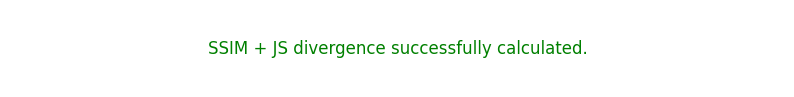

In [7]:
# --- Define Helper Functions ---
def rmse(y_true, y_pred):
    """Calculates the Root Mean Squared Error."""
    return np.sqrt(mean_squared_error(y_true, y_pred))

def rasterize_gene(coords, gene_vector, grid_size=(64, 64)):
    """Converts spot-based gene expression into a 2D grid representation using spatial coordinates."""
    x_coords, y_coords = coords[:, 0], coords[:, 1]
    sums, _, _ = np.histogram2d(x_coords, y_coords, bins=grid_size, weights=gene_vector)
    counts, _, _ = np.histogram2d(x_coords, y_coords, bins=grid_size)
    with np.errstate(divide='ignore', invalid='ignore'):
        image = sums / counts
    image[np.isnan(image)] = 0
    return image

def js_divergence(p, q):
    """Computes the Jensen–Shannon divergence between two non-negative vectors."""
    p = np.asarray(p, dtype=np.float64)
    q = np.asarray(q, dtype=np.float64)
    
    p_sum, q_sum = np.sum(p), np.sum(q)
    if p_sum == 0 or q_sum == 0:
        return np.nan

    p /= p_sum
    q /= q_sum
    m = 0.5 * (p + q)

    def kl_div(a, b):
        mask = (a > 0) & (b > 0)
        return np.sum(a[mask] * np.log(a[mask] / b[mask]))

    return 0.5 * kl_div(p, m) + 0.5 * kl_div(q, m)

def calculate_all_metrics(predictions_df, ground_truth_df, adata, model_name, dataset_name):
    """Computes metrics including JS divergence and SSIM with proper scaling, without modifying inputs."""
    common_genes = predictions_df.columns.intersection(ground_truth_df.columns)
    coords = adata.obs[['center_x', 'center_y']].values

    results = {}
    desc = f"🔁 Computing {model_name} metrics for {dataset_name}"
    for gene in tqdm(common_genes, desc=desc):
        # Copy to avoid in-place mutation of original predictions
        x = predictions_df[gene].values.copy()
        y = ground_truth_df[gene].values.copy()

        # --- Core Metrics ---
        pearson_r, _ = st.pearsonr(x, y)
        spearman_r, _ = st.spearmanr(x, y)
        rmse_val = rmse(y, x)
        norm_x, norm_y = np.linalg.norm(x), np.linalg.norm(y)
        cosine_sim = np.dot(x, y) / (norm_x * norm_y) if norm_x > 0 and norm_y > 0 else 0
        js_val = js_divergence(x, y)

        # # --- SSIM with 0–1 gene-wise scaling ---
        # ssim_val = np.nan
        # try:
        #     x_scaled = x / x.max() if x.max() > 0 else x
        #     y_scaled = y / y.max() if y.max() > 0 else y

        #     x_img = rasterize_gene(coords, x_scaled, grid_size=(64, 64))
        #     y_img = rasterize_gene(coords, y_scaled, grid_size=(64, 64))
        #     data_range = 1.0  # SSIM inputs already scaled to [0,1]
        #     ssim_val = ssim(x_img, y_img, data_range=data_range, win_size=5)
        # except Exception:
        #     pass

        # --- SSIM (vector-based, matching paper) ---
        x_scaled = x / x.max() if x.max() > 0 else x
        y_scaled = y / y.max() if y.max() > 0 else y

        mu_x = np.mean(x_scaled)
        mu_y = np.mean(y_scaled)
        sigma_x = np.var(x_scaled)
        sigma_y = np.var(y_scaled)
        cov_xy = np.cov(x_scaled, y_scaled)[0, 1]

        C1 = 0.01
        C2 = 0.03

        numerator = (2 * mu_x * mu_y + C1) * (2 * cov_xy + C2)
        denominator = (mu_x**2 + mu_y**2 + C1) * (sigma_x + sigma_y + C2)
        ssim_val = numerator / denominator if denominator > 0 else np.nan

        results[gene] = {
            'pearson_r': pearson_r,
            'spearman_r': spearman_r,
            'RMSE': rmse_val,
            'cosine_sim': cosine_sim,
            'js': js_val,
            'ssim': ssim_val,
        }

    return pd.DataFrame.from_dict(results, orient='index')



# --- Textual Output Block ---
print("--- Re-calculating Metrics with Corrected SSIM and JS Divergence ---")

# --- Dataset 1 Calculations ---
tangram_metrics_d1 = calculate_all_metrics(adata_1.obsm['tangram_predictions'], actual_gene_expression_d1, adata_1, "Tangram", "D1")
spage_metrics_d1   = calculate_all_metrics(adata_1.obsm['spage_predictions'], actual_gene_expression_d1, adata_1, "SpaGE", "D1")

# --- Dataset 2 Calculations ---
tangram_metrics_d2 = calculate_all_metrics(adata_2.obsm['tangram_predictions'], actual_gene_expression_d2, adata_2, "Tangram", "D2")
spage_metrics_d2   = calculate_all_metrics(adata_2.obsm['spage_predictions'], actual_gene_expression_d2, adata_2, "SpaGE", "D2")

print("\n--- Metric Calculation Complete ---")
print(f"Shape of tangram_metrics_d1: {tangram_metrics_d1.shape}")
print(f"Shape of spage_metrics_d1:   {spage_metrics_d1.shape}")
print(f"Shape of tangram_metrics_d2: {tangram_metrics_d2.shape}")
print(f"Shape of spage_metrics_d2:   {spage_metrics_d2.shape}")

print("\n--- Example SSIM values from tangram_metrics_d1 ---")
print(tangram_metrics_d1['ssim'].describe())

# --- Dummy Visualization ---
plt.figure(figsize=(10, 1))
plt.text(0.5, 0.5, 'SSIM + JS divergence successfully calculated.',
         ha='center', va='center', fontsize=12, color='green')
plt.gca().axis('off')
sns.despine(left=True, bottom=True, top=True, right=True)
plt.show()



In [8]:
# --- Helper function to ensure sparsity data exists ---
def ensure_sparsity_calculated(adata, adata_name):
    """Checks for a 'sparsity' column in adata.var and calculates it if missing."""
    if 'sparsity' not in adata.var.columns:
        print(f"INFO: 'sparsity' not found in {adata_name}.var. Calculating now...")
        # Sparsity = fraction of cells/spots with zero expression for each gene
        zero_counts_per_gene = adata.shape[0] - np.count_nonzero(adata.X, axis=0)
        adata.var['sparsity'] = zero_counts_per_gene / adata.shape[0]
    return adata

# --- Textual Output Block ---
print("--- Merging Sparsity Information into Metric DataFrames ---")

# --- Process Dataset 1 ---
print("\n--- Processing Dataset 1 ---")
# Ensure sparsity is calculated for both anndata objects
adata_1 = ensure_sparsity_calculated(adata_1, 'adata_1')
RNAseq_adata_1 = ensure_sparsity_calculated(RNAseq_adata_1, 'rnaseq_adata_1')

# Define common genes based on the metrics dataframe (which already used common genes)
common_genes_d1 = tangram_metrics_d1.index

# Extract sparsity as DataFrames
df_sparsity_sp_d1 = pd.DataFrame(
    adata_1[:, common_genes_d1].var["sparsity"]
).rename(columns={"sparsity": "sparsity_sp"})

df_sparsity_sc_d1 = pd.DataFrame(
    RNAseq_adata_1[:, common_genes_d1].var["sparsity"]
).rename(columns={"sparsity": "sparsity_sc"})

# Merge the two sparsity DataFrames
df_sparsity_d1 = df_sparsity_sp_d1.merge(
    df_sparsity_sc_d1, left_index=True, right_index=True
)
df_sparsity_d1["sparsity_diff"] = np.abs(df_sparsity_d1["sparsity_sp"] - df_sparsity_d1["sparsity_sc"])

# Merge with the existing metrics
tangram_gene_metrics_d1 = tangram_metrics_d1.merge(df_sparsity_d1, left_index=True, right_index=True)
spage_gene_metrics_d1 = spage_metrics_d1.merge(df_sparsity_d1, left_index=True, right_index=True)
print(f"Created 'tangram_gene_metrics_d1' with shape: {tangram_gene_metrics_d1.shape}")
print(f"Created 'spage_gene_metrics_d1' with shape: {spage_gene_metrics_d1.shape}")

# --- Process Dataset 2 ---
print("\n--- Processing Dataset 2 ---")
# Ensure sparsity is calculated
adata_2 = ensure_sparsity_calculated(adata_2, 'adata_2')
RNAseq_adata_2 = ensure_sparsity_calculated(RNAseq_adata_2, 'rnaseq_adata_2')

common_genes_d2 = tangram_metrics_d2.index

# Extract sparsity
df_sparsity_sp_d2 = pd.DataFrame(
    adata_2[:, common_genes_d2].var["sparsity"]
).rename(columns={"sparsity": "sparsity_sp"})

df_sparsity_sc_d2 = pd.DataFrame(
    RNAseq_adata_2[:, common_genes_d2].var["sparsity"]
).rename(columns={"sparsity": "sparsity_sc"})

# Merge sparsity
df_sparsity_d2 = df_sparsity_sp_d2.merge(
    df_sparsity_sc_d2, left_index=True, right_index=True
)
df_sparsity_d2["sparsity_diff"] = np.abs(df_sparsity_d2["sparsity_sp"] - df_sparsity_d2["sparsity_sc"])

# Merge with metrics
tangram_gene_metrics_d2 = tangram_metrics_d2.merge(df_sparsity_d2, left_index=True, right_index=True)
spage_gene_metrics_d2 = spage_metrics_d2.merge(df_sparsity_d2, left_index=True, right_index=True)
print(f"Created 'tangram_gene_metrics_d2' with shape: {tangram_gene_metrics_d2.shape}")
print(f"Created 'spage_gene_metrics_d2' with shape: {spage_gene_metrics_d2.shape}")

# --- Final Check ---
print("\n--- Example DataFrame Info (tangram_gene_metrics_d1) ---")
tangram_gene_metrics_d1.info()



--- Merging Sparsity Information into Metric DataFrames ---

--- Processing Dataset 1 ---
Created 'tangram_gene_metrics_d1' with shape: (464, 9)
Created 'spage_gene_metrics_d1' with shape: (464, 9)

--- Processing Dataset 2 ---
Created 'tangram_gene_metrics_d2' with shape: (296, 9)
Created 'spage_gene_metrics_d2' with shape: (296, 9)

--- Example DataFrame Info (tangram_gene_metrics_d1) ---
<class 'pandas.core.frame.DataFrame'>
Index: 464 entries, 4930452b06rik to wnt7b
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   pearson_r      464 non-null    float64
 1   spearman_r     464 non-null    float64
 2   RMSE           464 non-null    float64
 3   cosine_sim     464 non-null    float64
 4   js             464 non-null    float64
 5   ssim           464 non-null    float64
 6   sparsity_sp    464 non-null    float64
 7   sparsity_sc    464 non-null    float64
 8   sparsity_diff  464 non-null    float64
dtypes: f

**(ii) Plot Comparing Multiple Metrics**
- Figure 2b

--- Summary of Mean ± Std for Performance Metrics ---
metric_display            PCC       Spearman             JS           SSIM
label                                                                     
SpaGE (D1)      0.315 ± 0.200  0.241 ± 0.154  0.396 ± 0.163  0.648 ± 0.176
SpaGE (D2)      0.262 ± 0.178  0.228 ± 0.194  0.168 ± 0.137  0.414 ± 0.109
Tangram (D1)    0.314 ± 0.196  0.246 ± 0.156  0.405 ± 0.157  0.527 ± 0.209
Tangram (D2)    0.294 ± 0.178  0.237 ± 0.206  0.126 ± 0.112  0.501 ± 0.133


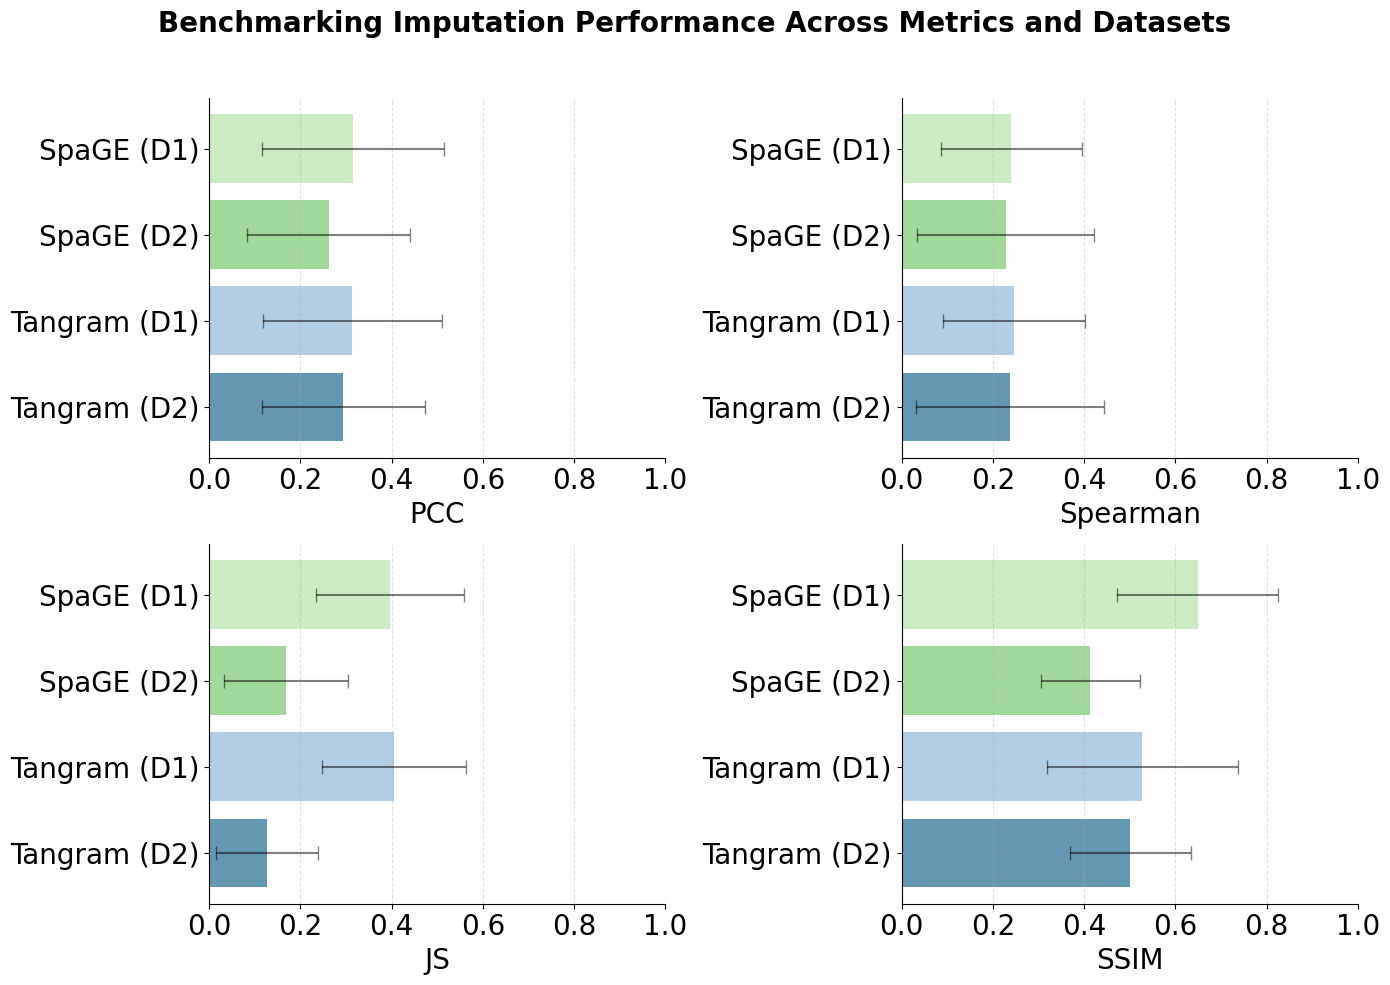

In [9]:
# --- 1. Combine all metric dataframes into a single tidy dataframe ---
tangram_metrics_d1['model'], tangram_metrics_d1['dataset'] = 'Tangram', 'D1'
spage_metrics_d1['model'], spage_metrics_d1['dataset'] = 'SpaGE', 'D1'
tangram_metrics_d2['model'], tangram_metrics_d2['dataset'] = 'Tangram', 'D2'
spage_metrics_d2['model'], spage_metrics_d2['dataset'] = 'SpaGE', 'D2'

all_metrics_list = [tangram_metrics_d1, spage_metrics_d1, tangram_metrics_d2, spage_metrics_d2]
combined_df = pd.concat(all_metrics_list)
combined_df['label'] = combined_df['model'] + " (" + combined_df['dataset'] + ")"

# --- 2. Calculate Mean and Standard Deviation for plotting ---
metrics_to_plot = ['pearson_r', 'spearman_r', 'js', 'ssim']
melted_df = combined_df.melt(
    id_vars=['label'],
    value_vars=metrics_to_plot,
    var_name='metric',
    value_name='value'
)
summary_stats = (
    melted_df.groupby(['label', 'metric'])['value']
    .agg(['mean', 'std']).reset_index()
)

metric_display_names = {
    'pearson_r': 'PCC',
    'spearman_r': 'Spearman',
    'js': 'JS',
    'ssim': 'SSIM'
}
summary_stats['metric_display'] = summary_stats['metric'].map(metric_display_names)

# --- Textual Output: Summary Table with ± Standard Deviation ---
print("--- Summary of Mean ± Std for Performance Metrics ---")
summary_stats['mean_std'] = summary_stats.apply(
    lambda row: f"{row['mean']:.3f} ± {row['std']:.3f}", axis=1
)
summary_with_error = summary_stats.pivot(
    index='label', columns='metric_display', values='mean_std'
)
print(summary_with_error[list(metric_display_names.values())])

# --- 3. Generate 2x2 Grid of Bar Plots with Custom Pastel Blue-Green Colours ---
fig, axes = plt.subplots(2, 2, figsize=(14, 10), constrained_layout=True)
axes = axes.flatten()

y_order = sorted(summary_stats['label'].unique(), reverse=True)

# Custom pastel shades of blue and green
custom_colours = {
    'Tangram (D1)': '#b3cde3',  # light blue
    'SpaGE (D1)': '#ccebc5',    # light green
    'Tangram (D2)': '#6497b1',  # muted denim
    'SpaGE (D2)': '#a1d99b',    # soft leafy green
}

for i, metric_name in enumerate(metric_display_names.values()):
    ax = axes[i]
    metric_data = summary_stats[summary_stats['metric_display'] == metric_name]
    metric_data = metric_data.set_index('label').loc[y_order]

    bar_colors = [custom_colours[label] for label in metric_data.index]

    ax.barh(
        metric_data.index,
        metric_data['mean'],
        xerr=metric_data['std'],
        align='center',
        color=bar_colors,
        capsize=5,
        error_kw={'alpha': 0.5}
    )

    ax.set_xlabel(metric_name, fontsize=20)
    ax.set_xlim(0, 1)
    ax.tick_params(axis='x', labelsize=20)
    ax.tick_params(axis='y', labelsize=20)
    ax.grid(axis='x', linestyle='--', alpha=0.4)

sns.despine()
plt.suptitle('Benchmarking Imputation Performance Across Metrics and Datasets', fontsize=20, weight='bold')
plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()

**(iii) Gene Qualitative Comparison Across Models**
- Plot Tangram and SpaGE differences across genes

In [8]:
from scipy.stats import pearsonr, spearmanr

target_gene = "ngb"
target_expn = adata_1[:, target_gene].X.copy()
tangram_pred = adata_1.obsm['tangram_predictions'][target_gene].values.copy()
spage_pred = adata_1.obsm['spage_predictions'][target_gene].values.copy()

target_expn = target_expn.ravel()
tangram_pred = tangram_pred.ravel()
spage_pred = spage_pred.ravel()

# Compute Pearson correlations and p-values
pearson_tangram_r, pearson_tangram_p = pearsonr(target_expn, tangram_pred)
pearson_spage_r, pearson_spage_p = pearsonr(target_expn, spage_pred)


# Print results
print(f"Pearson Tangram: r = {pearson_tangram_r:.4f}, p = {pearson_tangram_p:.4e}")
print(f"Pearson SpaGE:   r = {pearson_spage_r:.4f}, p = {pearson_spage_p:.4e}")

Pearson Tangram: r = 0.1948, p = 1.4398e-165
Pearson SpaGE:   r = 0.1618, p = 3.2936e-114


In [18]:
print(tangram_gene_metrics_d1[
    (tangram_gene_metrics_d1['sparsity_sp'] >= 0) &
    (tangram_gene_metrics_d1['sparsity_sp'] <= 0.3)
])


         pearson_r  spearman_r       RMSE  cosine_sim        js      ssim  \
aldoc     0.616013    0.621787   1.048348    0.938942  0.021194  0.680688   
cadm1     0.285013    0.291950   9.777000    0.942166  0.029767  0.517561   
chrm1     0.691334    0.680081   0.783470    0.919171  0.059883  0.734536   
chst1     0.624930    0.648477   0.846948    0.943459  0.035346  0.674425   
cxcl14    0.470736    0.399845   0.799356    0.798847  0.113651  0.624871   
elmod1    0.586605    0.558523   2.141275    0.909765  0.061198  0.660988   
grin2a    0.589132    0.565142   8.878677    0.894490  0.074750  0.637354   
grm3      0.491742    0.525159   6.570994    0.881586  0.068915  0.619935   
mfge8     0.689646    0.455789   0.784667    0.854003  0.100656  0.749458   
nefm      0.523064    0.532166   1.313533    0.884610  0.068106  0.551904   
nfix      0.397836    0.407521   1.263205    0.894331  0.059760  0.542869   
opcml     0.385720    0.359390  15.359175    0.833390  0.106356  0.436365   

In [13]:
tangram_gene_metrics_d1

,pearson_r,spearman_r,RMSE,cosine_sim,js,ssim,sparsity_sp,sparsity_sc,sparsity_diff
4930452b06rik,0.277350,0.347847,0.409055,0.543850,0.312490,0.310444,0.705108,0.934884,0.229776
5031425f14rik,0.016462,0.027458,0.097483,0.122197,0.630746,0.864553,0.972635,0.999145,0.026510
abcc9,0.584603,0.086094,0.370257,0.608678,0.387369,0.860381,0.898976,0.992211,0.093235
ackr1,0.431873,0.437174,0.357212,0.631958,0.275482,0.393148,0.669719,0.965849,0.296130
acta2,0.363550,0.029566,0.240607,0.389925,0.538362,0.898420,0.954889,0.995202,0.040313
...,...,...,...,...,...,...,...,...,...
vipr2,0.057325,0.044986,0.119462,0.119088,0.635591,0.617318,0.980402,0.992656,0.012254
vmn2r1,0.070198,0.094491,0.138133,0.216118,0.582059,0.651654,0.946916,0.988984,0.042067
vwc2,0.400850,0.278271,0.798612,0.492825,0.408151,0.480194,0.875315,0.926391,0.051076
wfs1,0.375448,0.339390,0.732799,0.697219,0.202548,0.523037,0.481405,0.946004,0.464599


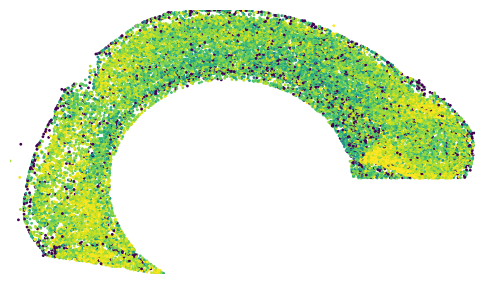

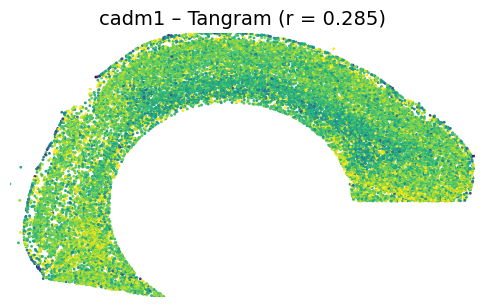

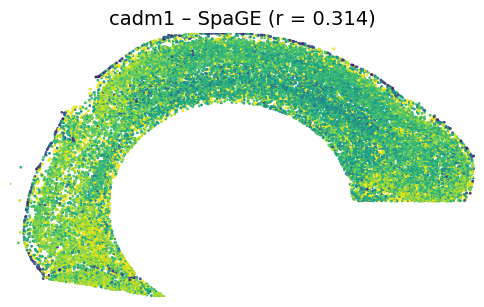

In [19]:
# --- Preprocess and set up ---
target_gene = "cadm1"
target_expn = adata_1[:, target_gene].X.copy()
tangram_pred = adata_1.obsm['tangram_predictions'][target_gene].values.copy()
spage_pred = adata_1.obsm['spage_predictions'][target_gene].values.copy()

def preprocess(arr):
    arr = arr.copy()
    arr[arr < 0] = 0
    arr = np.log1p(arr)
    vmax = np.percentile(arr, 95)
    arr[arr > vmax] = vmax
    return arr

target_expn = preprocess(target_expn)
tangram_pred = preprocess(tangram_pred)
spage_pred = preprocess(spage_pred)

x = adata_1.obs['center_x'].values
y = adata_1.obs['center_y'].values
xlim = [x.min(), x.max()]
ylim = [y.min(), y.max()]

# --- Plot Actual ---
fig, ax = plt.subplots(figsize=(6, 6))
ax.axis('off')
ax.scatter(x, y, s=1, c=target_expn, rasterized=True)
ax.set_xlim(xlim)
ax.set_ylim(ylim)
ax.set_aspect('equal')
# ax.set_title(f"{target_gene} – Actual Expression", fontsize=14)
plt.show()

# --- Plot Tangram ---
fig, ax = plt.subplots(figsize=(6, 6))
ax.axis('off')
ax.scatter(x, y, s=1, c=tangram_pred, rasterized=True)
ax.set_xlim(xlim)
ax.set_ylim(ylim)
ax.set_aspect('equal')
ax.set_title(f"{target_gene} – Tangram (r = {tangram_metrics_d1.loc[target_gene, 'pearson_r']:.3f})", fontsize=14)
plt.show()

# --- Plot SpaGE ---
fig, ax = plt.subplots(figsize=(6, 6))
ax.axis('off')
ax.scatter(x, y, s=1, c=spage_pred, rasterized=True)
ax.set_xlim(xlim)
ax.set_ylim(ylim)
ax.set_aspect('equal')
ax.set_title(f"{target_gene} – SpaGE (r = {spage_metrics_d1.loc[target_gene, 'pearson_r']:.3f})", fontsize=14)
plt.show()


**(iv) Permutations Test For Significantly Predicted Genes**

In [9]:
def perform_permutation_analysis(predictions_df, ground_truth_adata, metrics_df, model_name, dataset_name):
    """
    Performs permutation testing and returns the updated metrics_df AND a list of significant gene names.
    """
    print(f"\n--- Running Permutation Analysis for {model_name} on {dataset_name} ---")
    
    common_genes = predictions_df.columns.intersection(ground_truth_adata.var_names)
    actual_matrix = ground_truth_adata[:, common_genes].X.toarray()
    pred_matrix = predictions_df[common_genes].values
    n_cells, n_genes = pred_matrix.shape
    n_permutations = 999

    observed_pccs = np.array([st.pearsonr(pred_matrix[:, i], actual_matrix[:, i])[0] for i in range(n_genes)])
    
    null_pccs = np.zeros((n_permutations, n_genes))
    for i in tqdm(range(n_permutations), desc=f"Permutations: {model_name} ({dataset_name})"):
        shuffled_idx = np.random.permutation(n_cells)
        shuffled_preds = pred_matrix[shuffled_idx, :]
        null_pccs[i, :] = [st.pearsonr(shuffled_preds[:, j], actual_matrix[:, j])[0] for j in range(n_genes)]

    p_values = (np.sum(null_pccs >= observed_pccs[None, :], axis=0) + 1) / (n_permutations + 1)
    fdr_results = multipletests(p_values, alpha=0.05, method='fdr_bh')
    
    metrics_df.loc[common_genes, 'p_value'] = p_values
    metrics_df.loc[common_genes, 'fdr_p_value'] = fdr_results[1]
    metrics_df.loc[common_genes, 'significant_fdr'] = fdr_results[0].astype(bool)
    
    # Extract and return the list of significant genes
    significant_genes = metrics_df[metrics_df['significant_fdr'] == True].index.tolist()
    
    return metrics_df, significant_genes

In [73]:
# --- Run Analysis for all four conditions ---
# We now capture two outputs from the function for each call
tangram_gene_metrics_d1, tg_sig_genes_d1 = perform_permutation_analysis(adata_1.obsm['tangram_predictions'], adata_1, tangram_gene_metrics_d1, "Tangram", "D1")
spage_gene_metrics_d1, sp_sig_genes_d1 = perform_permutation_analysis(adata_1.obsm['spage_predictions'], adata_1, spage_gene_metrics_d1, "SpaGE", "D1")
tangram_gene_metrics_d2, tg_sig_genes_d2 = perform_permutation_analysis(adata_2.obsm['tangram_predictions'], adata_2, tangram_gene_metrics_d2, "Tangram", "D2")
spage_gene_metrics_d2, sp_sig_genes_d2 = perform_permutation_analysis(adata_2.obsm['spage_predictions'], adata_2, spage_gene_metrics_d2, "SpaGE", "D2")

# --- Save Significant Gene Lists ---
significant_gene_lists = {
    "tangram_d1": tg_sig_genes_d1,
    "spage_d1": sp_sig_genes_d1,
    "tangram_d2": tg_sig_genes_d2,
    "spage_d2": sp_sig_genes_d2
}


--- Running Permutation Analysis for Tangram on D1 ---


Permutations: Tangram (D1): 100%|██████████| 999/999 [20:50<00:00,  1.25s/it]



--- Running Permutation Analysis for SpaGE on D1 ---


Permutations: SpaGE (D1): 100%|██████████| 999/999 [20:23<00:00,  1.23s/it]



--- Running Permutation Analysis for Tangram on D2 ---


Permutations: Tangram (D2): 100%|██████████| 999/999 [1:48:13<00:00,  6.50s/it]   



--- Running Permutation Analysis for SpaGE on D2 ---


Permutations: SpaGE (D2): 100%|██████████| 999/999 [2:40:39<00:00,  9.65s/it]   


In [76]:
output_path = "/Users/Amith/Documents/Documents – Viji’s MacBook Pro/Work/LIDo PhD/Year 1/Rotation 2/Project Work/Code/Imputation_Comparison/" # Files will be saved in the current directory. Change if needed.

print("\n--- Saving Significant Gene Lists (FDR < 0.05) ---")
for name, gene_list in significant_gene_lists.items():
    filename = f"significant_genes_{name}.txt"
    filepath = output_path + filename
    with open(filepath, 'w') as f:
        for gene in gene_list:
            f.write(f"{gene}\n")
    print(f"Saved {len(gene_list)} genes to '{filepath}'")




--- Saving Significant Gene Lists (FDR < 0.05) ---
Saved 447 genes to '/Users/Amith/Documents/Documents – Viji’s MacBook Pro/Work/LIDo PhD/Year 1/Rotation 2/Project Work/Code/Imputation_Comparison/significant_genes_tangram_d1.txt'
Saved 445 genes to '/Users/Amith/Documents/Documents – Viji’s MacBook Pro/Work/LIDo PhD/Year 1/Rotation 2/Project Work/Code/Imputation_Comparison/significant_genes_spage_d1.txt'
Saved 281 genes to '/Users/Amith/Documents/Documents – Viji’s MacBook Pro/Work/LIDo PhD/Year 1/Rotation 2/Project Work/Code/Imputation_Comparison/significant_genes_tangram_d2.txt'
Saved 281 genes to '/Users/Amith/Documents/Documents – Viji’s MacBook Pro/Work/LIDo PhD/Year 1/Rotation 2/Project Work/Code/Imputation_Comparison/significant_genes_spage_d2.txt'


In [10]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

# --- 1. Calculate the proportion of significant genes for each condition ---
all_metrics_dfs = {
    "Tangram (D1)": tangram_gene_metrics_d1,
    "SpaGE (D1)": spage_gene_metrics_d1,
    "Tangram (D2)": tangram_gene_metrics_d2,
    "SpaGE (D2)": spage_gene_metrics_d2,
}

proportions_data = []
for label, df in all_metrics_dfs.items():
    significant_count = df['significant_fdr'].sum()
    total_count = len(df)
    proportion = significant_count / total_count if total_count > 0 else 0
    proportions_data.append({'Condition': label, 'Proportion': proportion})

# Create a DataFrame for plotting
plot_df = pd.DataFrame(proportions_data)

# --- 2. Textual Summary ---
print("--- Proportion of Significantly Predicted Genes (FDR < 0.05) ---")
for _, row in plot_df.iterrows():
    print(f"{row['Condition']:<15} | {row['Proportion']:.2%}")

# --- 3. Generate the Bar Chart ---
plt.figure(figsize=(10, 7))

# Use a pastel version of the YlOrRd palette (lightest to darkest)
custom_palette = sns.color_palette("BuPu", n_colors=4)

# Ensure order matches the palette
plot_order = ["Tangram (D1)", "SpaGE (D1)", "Tangram (D2)", "SpaGE (D2)"]

# Plot
ax = sns.barplot(data=plot_df, x='Condition', y='Proportion',
                 order=plot_order, palette=custom_palette,
                 edgecolor='black', linewidth=1.5)

# Add percentage labels on top of the bars
for i, p in enumerate(ax.patches):
    height = p.get_height()
    ax.annotate(f'{height:.1%}',
                (p.get_x() + p.get_width() / 2., height),
                ha='center', va='bottom',
                xytext=(0, 5),
                textcoords='offset points',
                fontsize=18)

# Formatting
ax.set_title('Proportion of Significantly Predicted Genes by Condition', fontsize=18)
ax.set_ylabel('Proportion of Genes (FDR < 0.05)', fontsize=20)
ax.set_xlabel('Condition', fontsize=20)
ax.set_ylim(0, max(plot_df['Proportion']) * 1.2)
ax.tick_params(axis='x', labelsize=20)
ax.tick_params(axis='y', labelsize=20)
ax.grid(axis='y', linestyle='--', alpha=0.6)

sns.despine()
plt.tight_layout()
plt.show()

#END

KeyError: 'significant_fdr'

--- Overlap Analysis for Dataset 1 ---
Genes Significant in BOTH models: 439
Genes Unique to Tangram: 8
Genes Unique to SpaGE: 6
Jaccard Similarity: 0.969
-----------------------------------
--- Overlap Analysis for Dataset 2 ---
Genes Significant in BOTH models: 276
Genes Unique to Tangram: 5
Genes Unique to SpaGE: 5
Jaccard Similarity: 0.965
-----------------------------------


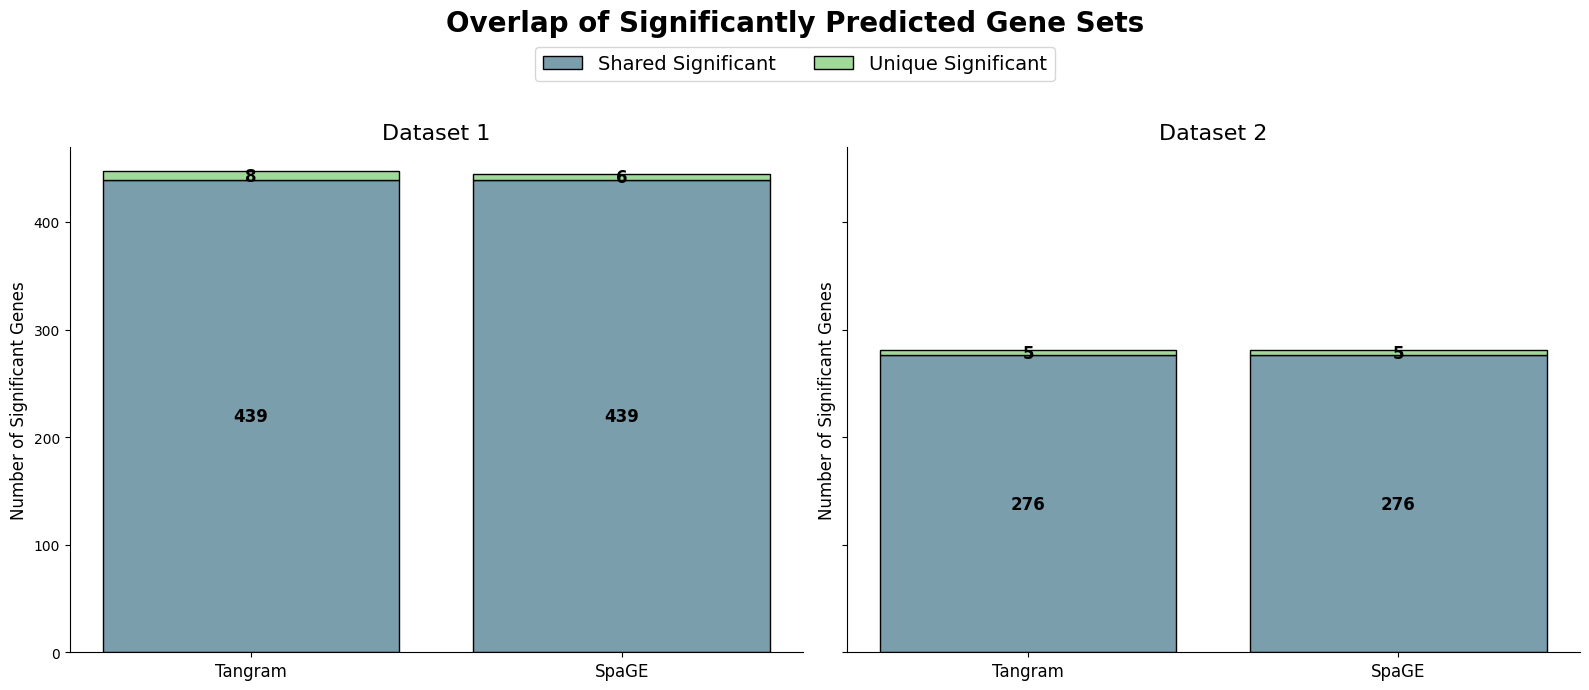

In [ ]:
# --- 1. Perform Set Operations and Summarize ---
def analyze_overlap(set1, set2, model1_name, model2_name, dataset_name):
    """Calculates and prints overlap statistics for two sets of genes."""
    intersection = len(set1.intersection(set2))
    union = len(set1.union(set2))
    unique_to_1 = len(set1.difference(set2))
    unique_to_2 = len(set2.difference(set1))
    jaccard = intersection / union if union > 0 else 0

    print(f"--- Overlap Analysis for {dataset_name} ---")
    print(f"Genes Significant in BOTH models: {intersection}")
    print(f"Genes Unique to {model1_name}: {unique_to_1}")
    print(f"Genes Unique to {model2_name}: {unique_to_2}")
    print(f"Jaccard Similarity: {jaccard:.3f}")
    print("-" * 35)
    return {'intersection': intersection, 'unique_model1': unique_to_1, 'unique_model2': unique_to_2}

# Convert lists to sets
set_tg_d1 = set(tg_sig_genes_d1); set_sp_d1 = set(sp_sig_genes_d1)
set_tg_d2 = set(tg_sig_genes_d2); set_sp_d2 = set(sp_sig_genes_d2)

# Get statistics for both datasets
data_d1 = analyze_overlap(set_tg_d1, set_sp_d1, "Tangram", "SpaGE", "Dataset 1")
data_d2 = analyze_overlap(set_tg_d2, set_sp_d2, "Tangram", "SpaGE", "Dataset 2")


# --- 2. Visualize with Stacked Bar Charts ---
fig, axes = plt.subplots(1, 2, figsize=(16, 7), sharey=True)
fig.suptitle('Overlap of Significantly Predicted Gene Sets', fontsize=20, weight='bold')

# Helper function for plotting
def plot_stacked_bar(ax, data, dataset_name):
    models = ['Tangram', 'SpaGE']
    shared_counts = [data['intersection'], data['intersection']]
    unique_counts = [data['unique_model1'], data['unique_model2']]
    
    # Plot the 'Shared' part (bottom)
    ax.bar(models, shared_counts, label='Shared Significant', color='#7b9ead', edgecolor='black', linewidth=1)
    
    # Plot the 'Unique' part (on top)
    ax.bar(models, unique_counts, bottom=shared_counts, label='Unique Significant', color='#a1d99b', edgecolor='black', linewidth=1)
    
    ax.set_title(dataset_name, fontsize=16)
    ax.set_ylabel('Number of Significant Genes', fontsize=12)
    ax.tick_params(axis='x', labelsize=12)
    
    # Add text labels
    for i, bar in enumerate(ax.patches):
        height = bar.get_height()
        if height > 0:
            ax.text(bar.get_x() + bar.get_width() / 2,
                    bar.get_y() + height / 2,
                    f'{int(height)}',
                    ha='center', va='center',
                    fontsize=12, color='black', weight='bold')

# Create plots for both datasets
plot_stacked_bar(axes[0], data_d1, "Dataset 1")
plot_stacked_bar(axes[1], data_d2, "Dataset 2")

# Create a single legend for the figure
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='upper center', bbox_to_anchor=(0.5, 0.94), ncol=2, fontsize=14)

sns.despine()
plt.tight_layout(rect=[0, 0, 1, 0.9]) # Adjust layout to make space for legend
plt.show()


#END

--- Statistical Comparison of Model Performance (Wilcoxon Signed-Rank Test) ---
Dataset      | Metric          |  W-statistic |      p-value | Conclusion (p < 0.05)       
---------------------------------------------------------------------------------------
Dataset 1    | PCC             |     47549.00 |   2.7003e-02 | Significant (SpaGE > Tangram)
Dataset 1    | Spearman        |     46726.00 |   1.2551e-02 | Significant (Tangram > SpaGE)
Dataset 1    | JS Divergence   |     35975.00 |   5.0866e-10 | Significant (SpaGE > Tangram)
Dataset 1    | SSIM            |     12093.00 |   1.6146e-47 | Significant (SpaGE > Tangram)
Dataset 2    | PCC             |      9254.00 |   5.9596e-18 | Significant (Tangram > SpaGE)
Dataset 2    | Spearman        |     17990.00 |   6.8123e-03 | Significant (Tangram > SpaGE)
Dataset 2    | JS Divergence   |       920.00 |   2.5998e-46 | Significant (Tangram > SpaGE)
Dataset 2    | SSIM            |      7915.00 |   1.4032e-21 | Significant (Tangram > Spa

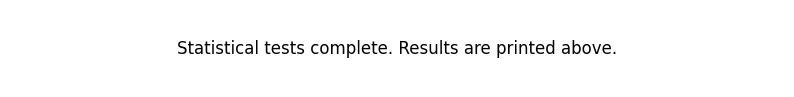

In [11]:
import pandas as pd
import numpy as np
from scipy.stats import wilcoxon # This line was missing or not executed.
import matplotlib.pyplot as plt
import seaborn as sns

# --- Textual Output Block ---
print("--- Statistical Comparison of Model Performance (Wilcoxon Signed-Rank Test) ---")

# Define the metrics and datasets we want to compare
metrics_to_test = {
    'pearson_r': 'PCC',
    'spearman_r': 'Spearman',
    'js': 'JS Divergence',
    'ssim': 'SSIM'
}

datasets = {
    "Dataset 1": (tangram_gene_metrics_d1, spage_gene_metrics_d1),
    "Dataset 2": (tangram_gene_metrics_d2, spage_gene_metrics_d2)
}

# Header for the results table
print(f"{'Dataset':<12} | {'Metric':<15} | {'W-statistic':>12} | {'p-value':>12} | {'Conclusion (p < 0.05)':<28}")
print("-" * 87)

for d_name, (tg_df, sp_df) in datasets.items():
    for metric_key, metric_name in metrics_to_test.items():
        comparison_df = pd.DataFrame({
            'tangram': tg_df[metric_key],
            'spage': sp_df[metric_key]
        }).dropna()

        if len(comparison_df) < 10:
            w_stat, p_val = np.nan, np.nan
            conclusion = "Not enough data"
        else:
            # Perform Wilcoxon
            w_stat, p_val = wilcoxon(comparison_df['tangram'], comparison_df['spage'])
            median_diff = (comparison_df['tangram'] - comparison_df['spage']).median()

            if p_val < 0.05:
                if metric_name == 'JS Divergence':  # lower is better
                    conclusion = "Significant (SpaGE > Tangram)" if median_diff > 0 else "Significant (Tangram > SpaGE)"
                else:  # higher is better
                    conclusion = "Significant (Tangram > SpaGE)" if median_diff > 0 else "Significant (SpaGE > Tangram)"
            else:
                conclusion = "No significant difference"

        print(f"{d_name:<12} | {metric_name:<15} | {w_stat:>12.2f} | {p_val:>12.4e} | {conclusion:<28}")



# --- Dummy Visualization ---
plt.figure(figsize=(10, 1))
plt.text(0.5, 0.5, 'Statistical tests complete. Results are printed above.',
         ha='center', va='center', fontsize=12)
plt.gca().axis('off')
sns.despine(left=True, bottom=True, top=True, right=True)
plt.show()

#END

--- Statistical Comparison of Performance Across Datasets (Mann-Whitney U Test) ---
Model      | Metric          |  U-statistic |      p-value | Conclusion (p < 0.05)       
---------------------------------------------------------------------------------------
Tangram    | PCC             |      71241.0 |   3.8413e-01 | No significant difference   
Tangram    | Spearman        |      68793.0 |   9.6743e-01 | No significant difference   
Tangram    | JS Divergence   |     125817.0 |   1.5904e-83 | Significant (D2 > D1)       
Tangram    | SSIM            |      74203.0 |   6.0937e-02 | No significant difference   
SpaGE      | PCC             |      78351.0 |   1.0401e-03 | Significant (D1 > D2)       
SpaGE      | Spearman        |      71921.0 |   2.7102e-01 | No significant difference   
SpaGE      | JS Divergence   |     118129.0 |   4.9672e-63 | Significant (D2 > D1)       
SpaGE      | SSIM            |     119551.0 |   1.3391e-66 | Significant (D1 > D2)       


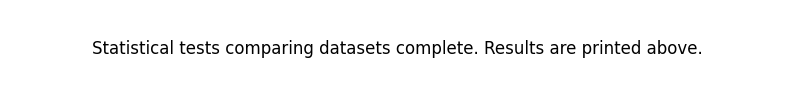

In [12]:
import pandas as pd
import numpy as np
from scipy.stats import mannwhitneyu
import matplotlib.pyplot as plt
import seaborn as sns

# --- Textual Output Block ---
print("--- Statistical Comparison of Performance Across Datasets (Mann-Whitney U Test) ---")

# Define metrics and models for the new comparison
metrics_to_test = {
    'pearson_r': 'PCC',
    'spearman_r': 'Spearman',
    'js': 'JS Divergence',
    'ssim': 'SSIM'
}

models_to_test = {
    "Tangram": (tangram_gene_metrics_d1, tangram_gene_metrics_d2),
    "SpaGE": (spage_gene_metrics_d1, spage_gene_metrics_d2)
}

# Header for the results table
print(f"{'Model':<10} | {'Metric':<15} | {'U-statistic':>12} | {'p-value':>12} | {'Conclusion (p < 0.05)':<28}")
print("-" * 87)

# Loop through each model and each metric
for model_name, (d1_df, d2_df) in models_to_test.items():
    for metric_key, metric_name in metrics_to_test.items():
        
        # Extract the independent samples (scores from D1 and D2)
        d1_scores = d1_df[metric_key].dropna()
        d2_scores = d2_df[metric_key].dropna()

        # Perform the Mann-Whitney U test
        u_stat, p_val = mannwhitneyu(d1_scores, d2_scores, alternative='two-sided')
        
        # Determine the conclusion
        if p_val < 0.05:
            median_d1 = d1_scores.median()
            median_d2 = d2_scores.median()
            
            # For JS Divergence, lower is better
            if metric_name == 'JS Divergence':
                conclusion = "Significant (D1 > D2)" if median_d1 < median_d2 else "Significant (D2 > D1)"
            # For all other metrics, higher is better
            else:
                conclusion = "Significant (D1 > D2)" if median_d1 > median_d2 else "Significant (D2 > D1)"
        else:
            conclusion = "No significant difference"
            
        # Print the formatted result row
        print(f"{model_name:<10} | {metric_name:<15} | {u_stat:>12.1f} | {p_val:>12.4e} | {conclusion:<28}")


# --- Dummy Visualization ---
plt.figure(figsize=(10, 1))
plt.text(0.5, 0.5, 'Statistical tests comparing datasets complete. Results are printed above.',
         ha='center', va='center', fontsize=12)
plt.gca().axis('off')
sns.despine(left=True, bottom=True, top=True, right=True)
plt.show()

#END

### **3. Determinants of Differential Gene Imputability**

In [10]:
# --- 1. Ensure Libraries are available ---
# !pip install esda libpysal tqdm

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from libpysal.weights import KNN
from esda.moran import Moran
from tqdm.auto import tqdm

# --- 2. Function to Calculate Moran's I only ---
def calculate_gene_properties(adata, dataset_name):
    """Calculates Moran's I for all genes, with a progress bar."""
    print(f"--- Calculating Moran's I for {dataset_name} ---")
    coords = adata.obs[['center_x', 'center_y']].values
    try:
        print("Pre-calculating spatial weights matrix...")
        wq = KNN.from_array(coords, k=6)
        wq.transform = 'r'
    except Exception as e:
        print(f"Warning: Could not create spatial weights matrix for {dataset_name}: {e}. Moran's I will be skipped.")
        wq = None

    new_properties = {}
    expression_matrix = adata.X.toarray() if hasattr(adata.X, 'toarray') else adata.X

    gene_iterator = tqdm(enumerate(adata.var_names), total=adata.n_vars, desc=f"Processing genes ({dataset_name})")
    for i, gene_name in gene_iterator:
        gene_expr = expression_matrix[:, i]
        props = {}
        if wq:
            try:
                mi = Moran(gene_expr, wq, permutations=0)
                props['moran_i'] = mi.I
            except Exception:
                props['moran_i'] = np.nan
        new_properties[gene_name] = props

    return pd.DataFrame.from_dict(new_properties, orient='index')

# --- 3. Compute Moran's I ---
props_d1 = calculate_gene_properties(adata_1, "Dataset 1")
props_d2 = calculate_gene_properties(adata_2, "Dataset 2")

# --- 4. Merge Only Needed Metrics ---
def prepare_analysis_df(gene_metrics_df, props_df, model, dataset):
    df = gene_metrics_df[['spearman_r', 'js', 'sparsity_sp']].join(props_df)
    df['model'] = model
    df['dataset'] = dataset
    return df

analysis_tg_d1 = prepare_analysis_df(tangram_gene_metrics_d1, props_d1, 'Tangram', 'D1')
analysis_sp_d1 = prepare_analysis_df(spage_gene_metrics_d1, props_d1, 'SpaGE', 'D1')
analysis_tg_d2 = prepare_analysis_df(tangram_gene_metrics_d2, props_d2, 'Tangram', 'D2')
analysis_sp_d2 = prepare_analysis_df(spage_gene_metrics_d2, props_d2, 'SpaGE', 'D2')

combined_df = pd.concat([analysis_tg_d1, analysis_sp_d1, analysis_tg_d2, analysis_sp_d2])

# --- 5. Print Correlation Matrices ---
for name, df in {
    "Tangram, D1": analysis_tg_d1,
    "SpaGE, D1": analysis_sp_d1,
    "Tangram, D2": analysis_tg_d2,
    "SpaGE, D2": analysis_sp_d2
}.items():
    print(f"\n--- Correlation Matrix: {name} ---")
    print(df[['sparsity_sp', 'moran_i', 'spearman_r']].corr().loc[['sparsity_sp', 'moran_i'], ['spearman_r']].round(3))

# # --- 6. Plotting: Moran's I & Sparsity vs. Spearman ---
# fig, axes = plt.subplots(1, 2, figsize=(16, 7))
# fig.suptitle("Spatial Determinants of Imputation Performance", fontsize=20, weight='bold')

# sns.lmplot(data=combined_df, x='moran_i', y='spearman_r', hue='model', style='dataset',
#            palette={'Tangram': '#ff6666', 'SpaGE': '#6497b1'},
#            markers=['o', 'X'],
#            line_kws={'linewidth': 2.5},
#            scatter_kws={'alpha': 0.2, 's': 20'})
# plt.close()

# sns.lmplot(data=combined_df, x='sparsity_sp', y='spearman_r', hue='model', style='dataset',
#            palette={'Tangram': '#ff6666', 'SpaGE': '#6497b1'},
#            markers=['o', 'X'],
#            line_kws={'linewidth': 2.5},
#            scatter_kws={'alpha': 0.2, 's': 20'})
# plt.close()

# # Copy the lmplot contents into subplots
# def manual_plot(ax, x, y, title, xlabel, ylabel):
#     sns.scatterplot(data=combined_df, x=x, y=y, hue='model', style='dataset',
#                     palette={'Tangram': '#ff6666', 'SpaGE': '#6497b1'},
#                     markers=['o', 'X'], alpha=0.2, s=20, ax=ax)
#     sns.regplot(data=combined_df, x=x, y=y, scatter=False,
#                 line_kws={'color': 'black', 'lw': 2}, ax=ax)
#     ax.set_title(title, fontsize=14)
#     ax.set_xlabel(xlabel)
#     ax.set_ylabel(ylabel)
#     ax.grid(True, linestyle='--', alpha=0.5)

# manual_plot(axes[0], 'moran_i', 'spearman_r', "Spatial Structure vs. Performance", "Moran's I", "Spearman Correlation")
# manual_plot(axes[1], 'sparsity_sp', 'spearman_r', "Sparsity vs. Performance", "Spatial Sparsity", "Spearman Correlation")

# sns.despine()
# plt.tight_layout(rect=[0, 0, 1, 0.95])
# plt.show()


--- Calculating Moran's I for Dataset 1 ---
Pre-calculating spatial weights matrix...


Processing genes (Dataset 1): 100%|██████████| 464/464 [00:33<00:00, 13.66it/s]


--- Calculating Moran's I for Dataset 2 ---
Pre-calculating spatial weights matrix...


Processing genes (Dataset 2): 100%|██████████| 296/296 [00:57<00:00,  5.14it/s]


--- Correlation Matrix: Tangram, D1 ---
             spearman_r
sparsity_sp      -0.782
moran_i           0.689

--- Correlation Matrix: SpaGE, D1 ---
             spearman_r
sparsity_sp      -0.744
moran_i           0.705

--- Correlation Matrix: Tangram, D2 ---
             spearman_r
sparsity_sp       0.039
moran_i           0.674

--- Correlation Matrix: SpaGE, D2 ---
             spearman_r
sparsity_sp      -0.118
moran_i           0.716


--- Statistical Test for Differences in Gene Property Distributions ---
--- (Mann-Whitney U Test) ---
Property             |  U-statistic |      p-value | Conclusion (p < 0.05)
---------------------------------------------------------------------------
Spatial Sparsity     |     128122.0 |     3.05e-90 | Significant difference
Morans I             |      50882.0 |     1.66e-09 | Significant difference


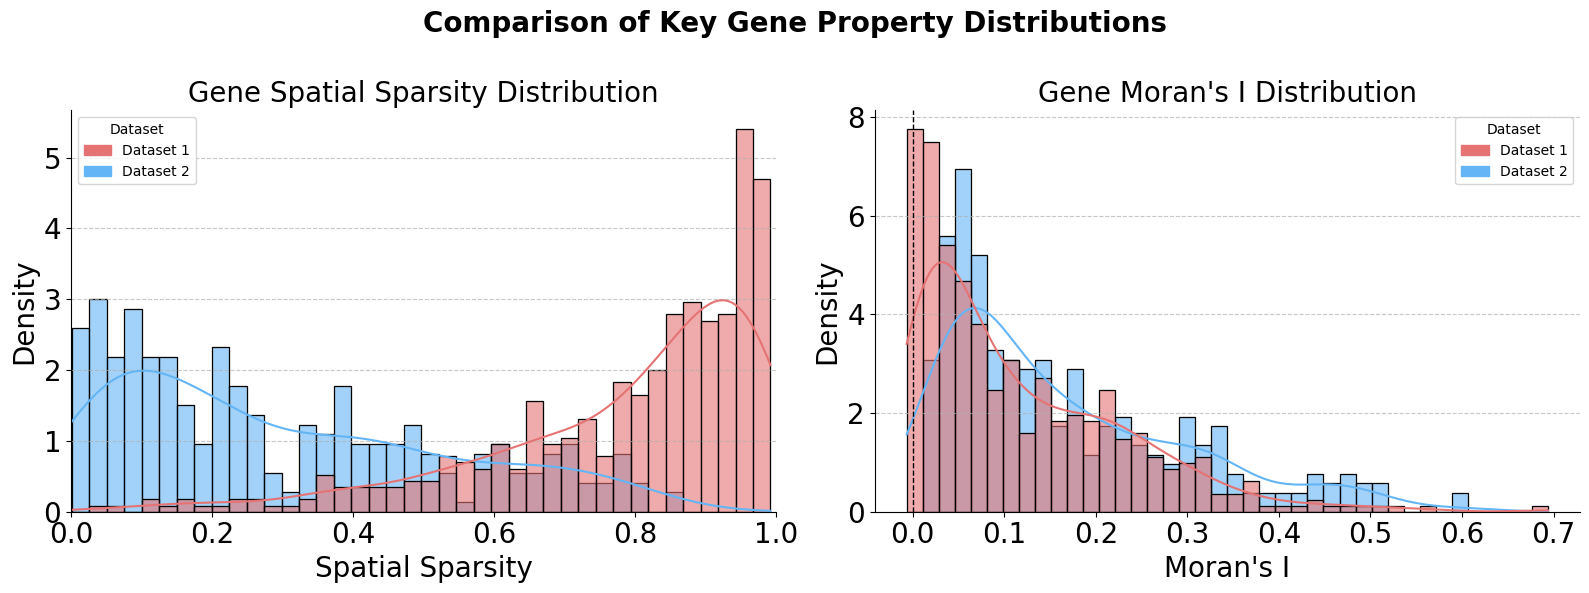

In [11]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.stats import mannwhitneyu

# --- 1. Data Preparation ---
try:
    # Get a unique list of gene properties for each dataset
    combined_df['label'] = combined_df['model'] + " (" + combined_df['dataset'] + ")"
    props_d1 = combined_df[combined_df['label'] == 'Tangram (D1)'][['sparsity_sp', 'moran_i']].dropna()
    props_d2 = combined_df[combined_df['label'] == 'Tangram (D2)'][['sparsity_sp', 'moran_i']].dropna()
    
    plot_df = pd.concat([
        props_d1.assign(dataset='Dataset 1'),
        props_d2.assign(dataset='Dataset 2')
    ])
except NameError:
    print("FATAL ERROR: The 'combined_analysis_df' DataFrame was not found.")
    exit()

# --- 2. Perform and Summarize Statistical Tests ---
print("--- Statistical Test for Differences in Gene Property Distributions ---")
print("--- (Mann-Whitney U Test) ---")

# Test for Sparsity
u_stat_sp, p_val_sp = mannwhitneyu(props_d1['sparsity_sp'], props_d2['sparsity_sp'], alternative='two-sided')
conclusion_sp = "Significant difference" if p_val_sp < 0.05 else "No significant difference"

# Test for Moran's I
u_stat_mi, p_val_mi = mannwhitneyu(props_d1['moran_i'], props_d2['moran_i'], alternative='two-sided')
conclusion_mi = "Significant difference" if p_val_mi < 0.05 else "No significant difference"

# Print results table
print(f"{'Property':<20} | {'U-statistic':>12} | {'p-value':>12} | {'Conclusion (p < 0.05)'}")
print("-" * 75)
print(f"{'Spatial Sparsity':<20} | {u_stat_sp:>12.1f} | {p_val_sp:>12.2e} | {conclusion_sp}")
print(f"{'Morans I':<20} | {u_stat_mi:>12.1f} | {p_val_mi:>12.2e} | {conclusion_mi}")


# --- 3. Generate 1x2 Figure of Distributions ---
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
fig.suptitle('Comparison of Key Gene Property Distributions', fontsize=20, weight='bold')
palette = {'Dataset 1': '#E57373', 'Dataset 2': '#64B5F6'}

# Left Plot: Sparsity
sns.histplot(data=plot_df, x='sparsity_sp', hue='dataset', bins=40, stat='density', common_norm=False, palette=palette, alpha=0.6, kde=True, ax=axes[0])
axes[0].set_title('Gene Spatial Sparsity Distribution', fontsize=20); axes[0].set_xlabel('Spatial Sparsity', fontsize=20); axes[0].set_ylabel('Density', fontsize=20); axes[0].set_xlim(0, 1); axes[0].tick_params(labelsize=20)

# Right Plot: Moran's I
sns.histplot(data=plot_df, x='moran_i', hue='dataset', bins=40, stat='density', common_norm=False, palette=palette, alpha=0.6, kde=True, ax=axes[1])
axes[1].set_title("Gene Moran's I Distribution", fontsize=20); axes[1].set_xlabel("Moran's I", fontsize=20); axes[1].set_ylabel('Density', fontsize=20); axes[1].axvline(0, color='black', lw=1, linestyle='--'); axes[1].tick_params(labelsize=20)

# Final formatting
handles = [plt.Rectangle((0,0),1,1, color=palette[l]) for l in ['Dataset 1', 'Dataset 2']]
for ax in axes:
    ax.grid(axis='y', linestyle='--', alpha=0.7)
    ax.legend(handles=handles, labels=['Dataset 1', 'Dataset 2'], title='Dataset')

sns.despine()
plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

#END

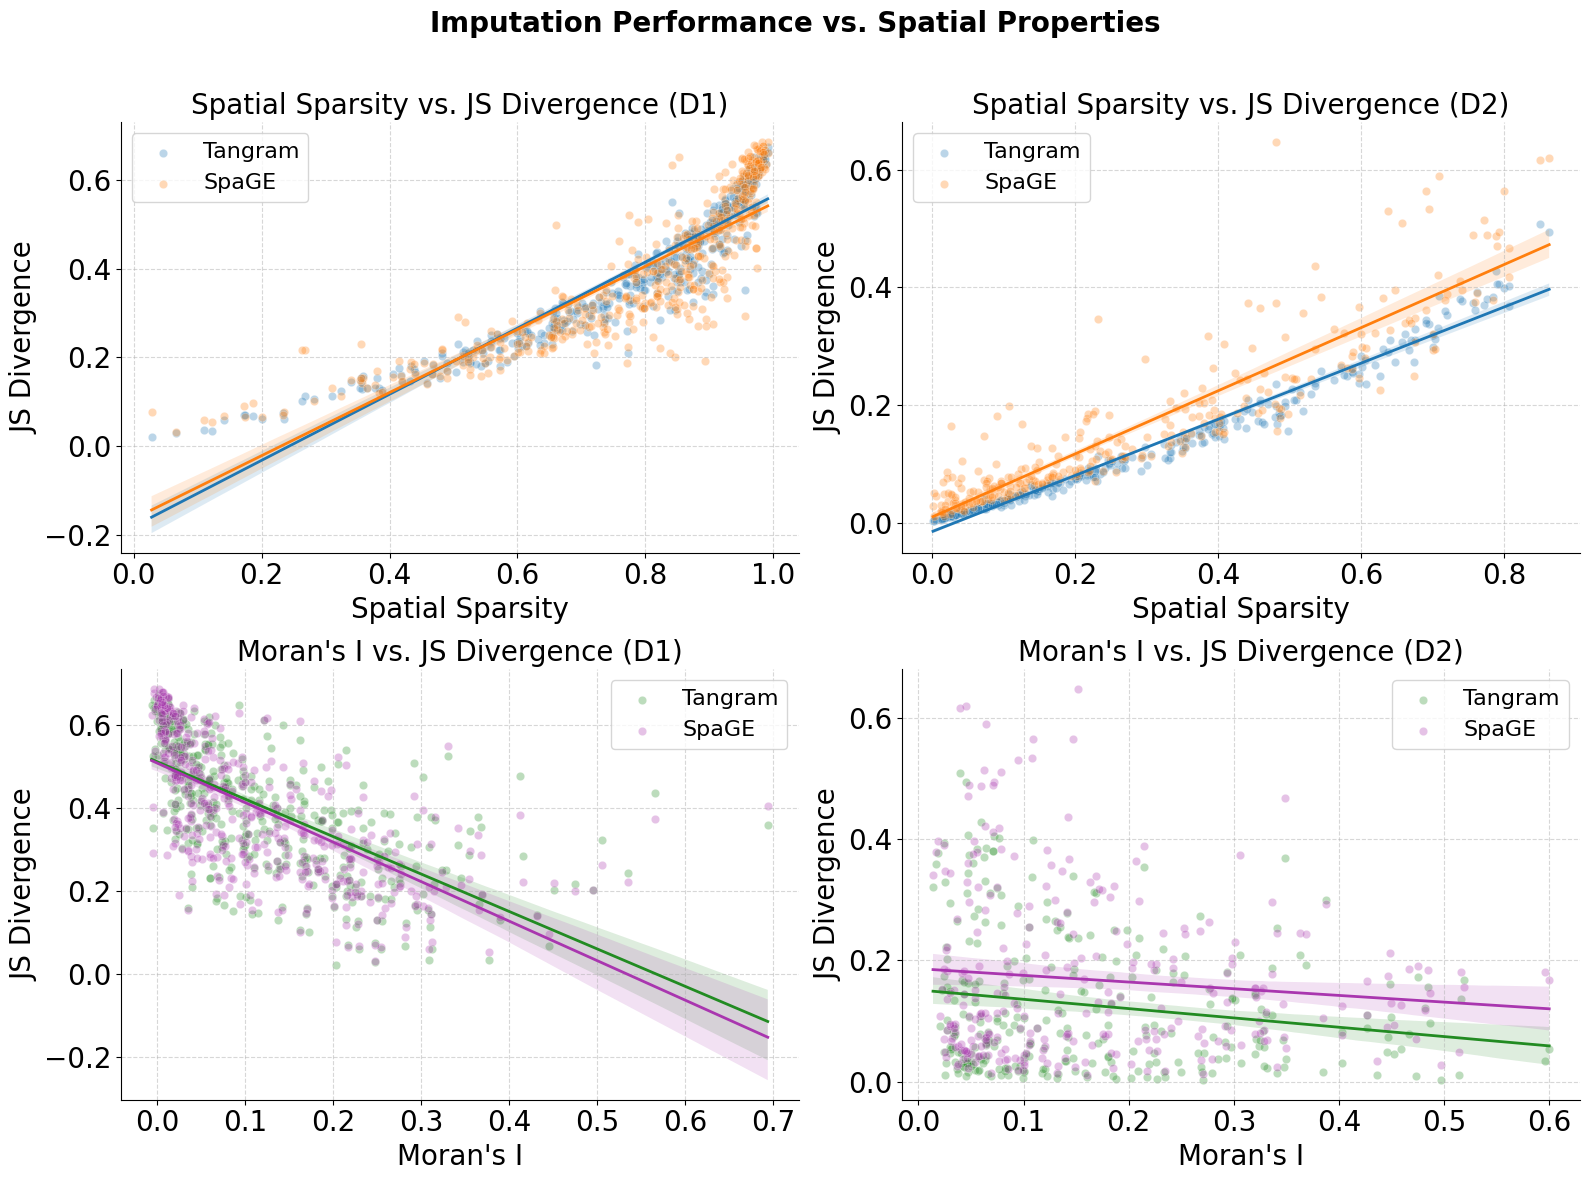

In [12]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set up 2x2 grid
fig, axes = plt.subplots(2, 2, figsize=(16, 12))
fig.suptitle("Imputation Performance vs. Spatial Properties", fontsize=20, weight='bold')

# Colour palette now based on metric and model
palette = {
    ('sparsity_sp', 'Tangram'): '#1f77b4',  # blue
    ('sparsity_sp', 'SpaGE'):   '#ff7f0e',  # orange
    ('moran_i', 'Tangram'):     '#228B22',  # forest green
    ('moran_i', 'SpaGE'):       '#A936AF'   # magenta
}

datasets = ['D1', 'D2']
metrics = [('sparsity_sp', 'Spatial Sparsity', 'Sparsity'), 
           ('moran_i', "Moran's I", 'Spatial Structure')]

# Row 0: Moran’s I vs Spearman | Row 1: Sparsity vs Spearman
for row, (x_var, x_label, title_prefix) in enumerate(metrics):
    for col, dataset in enumerate(datasets):
        ax = axes[row, col]
        subset = combined_df[combined_df['dataset'] == dataset]

        # Scatter + regression per model
        for model in ['Tangram', 'SpaGE']:
            data = subset[subset['model'] == model]
            colour = palette[(x_var, model)]

            sns.scatterplot(
                x=x_var, y='js', data=data,
                ax=ax, color=colour, alpha=0.3, label=model
            )
            sns.regplot(
                x=x_var, y='js', data=data,
                ax=ax, scatter=False, color=colour, line_kws={'lw': 2}
            )
        ax.set_title(f"{x_label} vs. JS Divergence ({dataset})", fontsize=20)
        ax.set_xlabel(x_label, fontsize=20)
        ax.set_ylabel("JS Divergence", fontsize=20)
        ax.tick_params(axis='both', labelsize=20)
        ax.grid(True, linestyle='--', alpha=0.5)
        ax.legend(fontsize=16)

sns.despine()
plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()


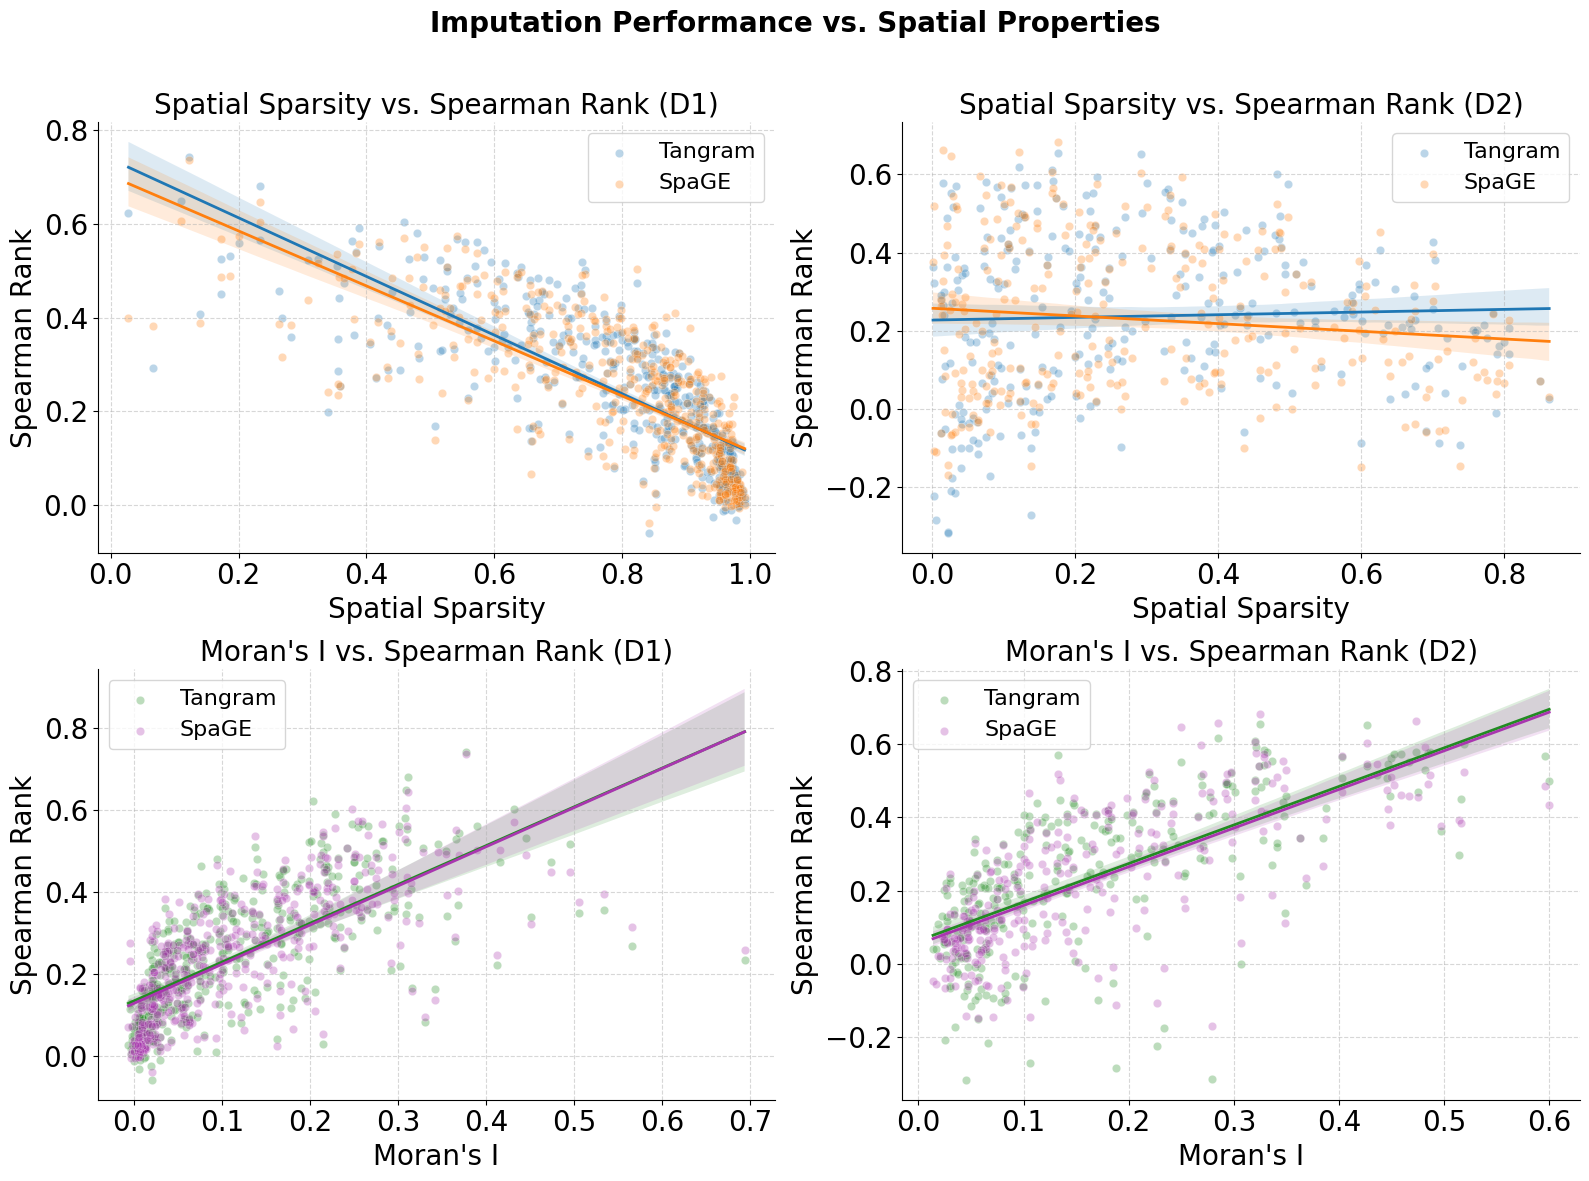

In [13]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set up 2x2 grid
fig, axes = plt.subplots(2, 2, figsize=(16, 12))
fig.suptitle("Imputation Performance vs. Spatial Properties", fontsize=20, weight='bold')

# Colour palette now based on metric and model
palette = {
    ('sparsity_sp', 'Tangram'): '#1f77b4',  # blue
    ('sparsity_sp', 'SpaGE'):   '#ff7f0e',  # orange
    ('moran_i', 'Tangram'):     '#228B22',  # forest green
    ('moran_i', 'SpaGE'):       '#A936AF'   # magenta
}

datasets = ['D1', 'D2']
metrics = [('sparsity_sp', 'Spatial Sparsity', 'Sparsity'), 
           ('moran_i', "Moran's I", 'Spatial Structure')]

# Row 0: Moran’s I vs Spearman | Row 1: Sparsity vs Spearman
for row, (x_var, x_label, title_prefix) in enumerate(metrics):
    for col, dataset in enumerate(datasets):
        ax = axes[row, col]
        subset = combined_df[combined_df['dataset'] == dataset]

        # Scatter + regression per model
        for model in ['Tangram', 'SpaGE']:
            data = subset[subset['model'] == model]
            colour = palette[(x_var, model)]

            sns.scatterplot(
                x=x_var, y='spearman_r', data=data,
                ax=ax, color=colour, alpha=0.3, label=model
            )
            sns.regplot(
                x=x_var, y='spearman_r', data=data,
                ax=ax, scatter=False, color=colour, line_kws={'lw': 2}
            )
        ax.set_title(f"{x_label} vs. Spearman Rank ({dataset})", fontsize=20)
        ax.set_xlabel(x_label, fontsize=20)
        ax.set_ylabel("Spearman Rank", fontsize=20)
        ax.tick_params(axis='both', labelsize=20)
        ax.grid(True, linestyle='--', alpha=0.5)
        ax.legend(fontsize=16)

sns.despine()
plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

--- Statistical Test of Performance Determinants (Pearson's r) ---
Condition       | Relationship (X vs Y)        |    Pearson r |      p-value
---------------------------------------------------------------------------
Tangram (D1)    | sparsity_sp vs spearman_r    |       -0.782 |     4.33e-97
Tangram (D1)    | moran_i vs spearman_r        |        0.689 |     1.69e-66
SpaGE (D1)      | sparsity_sp vs spearman_r    |       -0.744 |     4.49e-83
SpaGE (D1)      | moran_i vs spearman_r        |        0.705 |     5.35e-71
Tangram (D2)    | sparsity_sp vs spearman_r    |        0.039 |     5.09e-01
Tangram (D2)    | moran_i vs spearman_r        |        0.674 |     1.63e-40
SpaGE (D2)      | sparsity_sp vs spearman_r    |       -0.118 |     4.31e-02
SpaGE (D2)      | moran_i vs spearman_r        |        0.716 |     7.54e-48


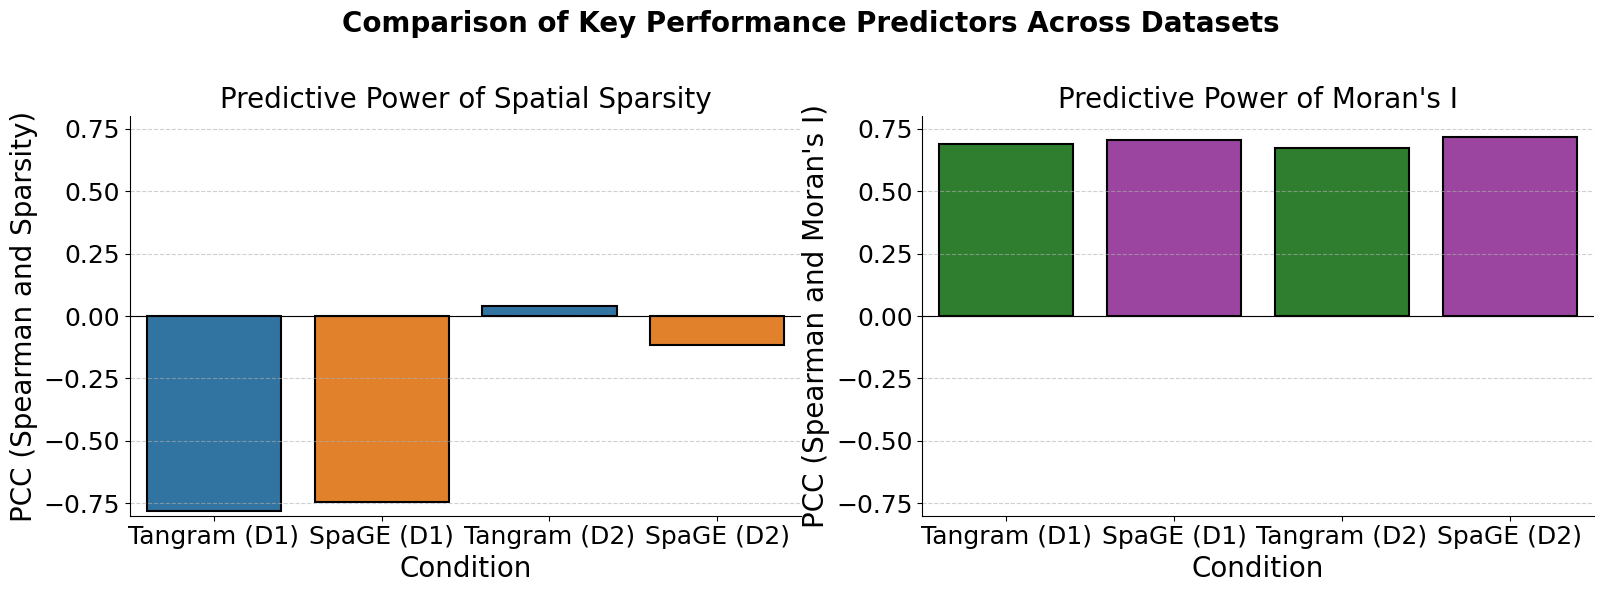

In [79]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.stats import pearsonr

# --- 1. Formal Statistical Testing for Correlations ---
print("--- Statistical Test of Performance Determinants (Pearson's r) ---")
print(f"{'Condition':<15} | {'Relationship (X vs Y)':<28} | {'Pearson r':>12} | {'p-value':>12}")
print("-" * 75)

try:
    if 'condition' not in combined_df.columns:
        combined_df['condition'] = combined_df['model'] + ' (' + combined_df['dataset'] + ')'
except NameError:
    print("FATAL ERROR: The 'combined_df' DataFrame was not found.")
    exit()

conditions_to_test = ["Tangram (D1)", "SpaGE (D1)", "Tangram (D2)", "SpaGE (D2)"]
relationships_to_test = [('sparsity_sp', 'spearman_r'), ('moran_i', 'spearman_r')]
results_for_plot = []

for name in conditions_to_test:
    df = combined_df[combined_df['condition'] == name]
    for x_col, y_col in relationships_to_test:
        test_data = df[[x_col, y_col]].dropna()
        if len(test_data) > 2:
            r_val, p_val = pearsonr(test_data[x_col], test_data[y_col])
            relationship_str = f"{x_col} vs {y_col}"
            print(f"{name:<15} | {relationship_str:<28} | {r_val:>12.3f} | {p_val:>12.2e}")
            results_for_plot.append({'Condition': name, 'Relationship': relationship_str, 'Correlation': r_val})

plot_df = pd.DataFrame(results_for_plot)

# --- 2. Targeted Visualization of Correlation Coefficients ---
fig, axes = plt.subplots(1, 2, figsize=(16, 6), sharey=False)  # <-- key change here
fig.suptitle("Comparison of Key Performance Predictors Across Datasets", fontsize=20, weight='bold')

# Palette based on metric
sparsity_palette = {
    'Tangram (D1)': '#1f77b4',  # blue
    'SpaGE (D1)':   '#ff7f0e',  # orange
    'Tangram (D2)': '#1f77b4',  # same blue
    'SpaGE (D2)':   '#ff7f0e'   # same orange
}
moran_palette = {
    'Tangram (D1)': '#228B22',  # forest green
    'SpaGE (D1)':   '#A936AF',  # magenta
    'Tangram (D2)': '#228B22',  # same green
    'SpaGE (D2)':   '#A936AF'   # same magenta
}

# Left Plot: Sparsity
ax1 = sns.barplot(
    data=plot_df[plot_df['Relationship'] == 'sparsity_sp vs spearman_r'],
    x='Condition', y='Correlation', palette=sparsity_palette, ax=axes[0],
    edgecolor='black', linewidth=1.5
)
ax1.set_title("Predictive Power of Spatial Sparsity", fontsize=20)
ax1.set_xlabel("Condition", fontsize=20)
ax1.set_ylabel("PCC (Spearman and Sparsity)", fontsize=20)
ax1.axhline(0, color='black', lw=0.8)
ax1.set_ylim(-0.8, 0.8)
ax1.tick_params(axis='x', labelsize=18)
ax1.tick_params(axis='y', labelsize=18)

# Right Plot: Moran’s I
ax2 = sns.barplot(
    data=plot_df[plot_df['Relationship'] == 'moran_i vs spearman_r'],
    x='Condition', y='Correlation', palette=moran_palette, ax=axes[1],
    edgecolor='black', linewidth=1.5
)
ax2.set_title("Predictive Power of Moran's I", fontsize=20)
ax2.set_xlabel("Condition", fontsize=20)
ax2.set_ylabel("PCC (Spearman and Moran's I)", fontsize=20)  # ✅ correct and visible now
ax2.axhline(0, color='black', lw=0.8)
ax2.set_ylim(-0.8, 0.8)
ax2.tick_params(axis='x', labelsize=18)
ax2.tick_params(axis='y', labelsize=18)

for ax in axes:
    ax.grid(axis='y', linestyle='--', alpha=0.6)

sns.despine()
plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()


--- Statistical Test of Performance Determinants (Pearson's r) ---
Condition       | Relationship (X vs Y)        |    Pearson r |      p-value
---------------------------------------------------------------------------
Tangram (D1)    | sparsity_sp vs js            |        0.924 |    9.69e-195
Tangram (D1)    | moran_i vs js                |       -0.648 |     1.37e-56
SpaGE (D1)      | sparsity_sp vs js            |        0.855 |    1.19e-133
SpaGE (D1)      | moran_i vs js                |       -0.663 |     5.86e-60
Tangram (D2)    | sparsity_sp vs js            |        0.985 |    8.14e-225
Tangram (D2)    | moran_i vs js                |       -0.180 |     1.92e-03
SpaGE (D2)      | sparsity_sp vs js            |        0.909 |    1.07e-113
SpaGE (D2)      | moran_i vs js                |       -0.106 |     6.92e-02


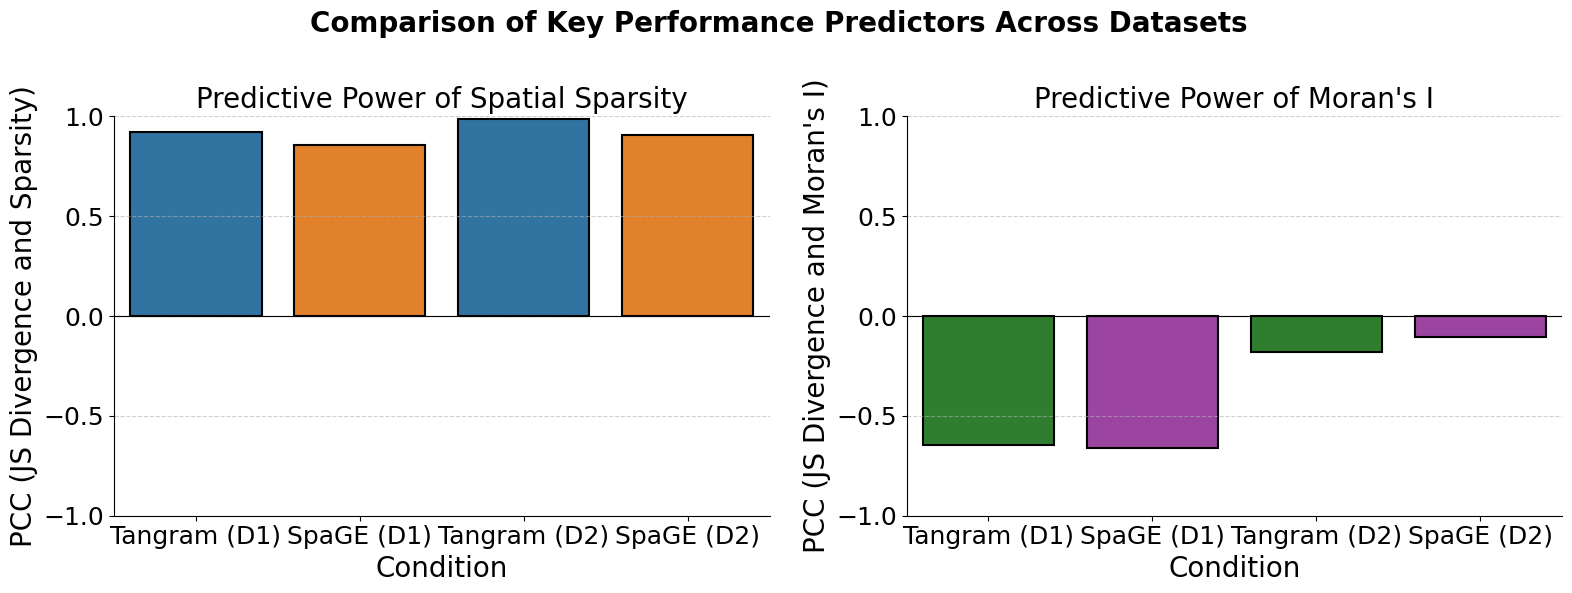

In [32]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.stats import pearsonr

# --- 1. Formal Statistical Testing for Correlations ---
print("--- Statistical Test of Performance Determinants (Pearson's r) ---")
print(f"{'Condition':<15} | {'Relationship (X vs Y)':<28} | {'Pearson r':>12} | {'p-value':>12}")
print("-" * 75)

try:
    if 'condition' not in combined_df.columns:
        combined_df['condition'] = combined_df['model'] + ' (' + combined_df['dataset'] + ')'
except NameError:
    print("FATAL ERROR: The 'combined_df' DataFrame was not found.")
    exit()

conditions_to_test = ["Tangram (D1)", "SpaGE (D1)", "Tangram (D2)", "SpaGE (D2)"]
relationships_to_test = [('sparsity_sp', 'js'), ('moran_i', 'js')]
results_for_plot = []

for name in conditions_to_test:
    df = combined_df[combined_df['condition'] == name]
    for x_col, y_col in relationships_to_test:
        test_data = df[[x_col, y_col]].dropna()
        if len(test_data) > 2:
            r_val, p_val = pearsonr(test_data[x_col], test_data[y_col])
            relationship_str = f"{x_col} vs {y_col}"
            print(f"{name:<15} | {relationship_str:<28} | {r_val:>12.3f} | {p_val:>12.2e}")
            results_for_plot.append({'Condition': name, 'Relationship': relationship_str, 'Correlation': r_val})

plot_df = pd.DataFrame(results_for_plot)

# --- 2. Targeted Visualization of Correlation Coefficients ---
fig, axes = plt.subplots(1, 2, figsize=(16, 6), sharey=False)  # <-- key change here
fig.suptitle("Comparison of Key Performance Predictors Across Datasets", fontsize=20, weight='bold')

# Palette based on metric
sparsity_palette = {
    'Tangram (D1)': '#1f77b4',  # blue
    'SpaGE (D1)':   '#ff7f0e',  # orange
    'Tangram (D2)': '#1f77b4',  # same blue
    'SpaGE (D2)':   '#ff7f0e'   # same orange
}
moran_palette = {
    'Tangram (D1)': '#228B22',  # forest green
    'SpaGE (D1)':   '#A936AF',  # magenta
    'Tangram (D2)': '#228B22',  # same green
    'SpaGE (D2)':   '#A936AF'   # same magenta
}

# Left Plot: Sparsity
ax1 = sns.barplot(
    data=plot_df[plot_df['Relationship'] == 'sparsity_sp vs js'],
    x='Condition', y='Correlation', palette=sparsity_palette, ax=axes[0],
    edgecolor='black', linewidth=1.5
)
ax1.set_title("Predictive Power of Spatial Sparsity", fontsize=20)
ax1.set_xlabel("Condition", fontsize=20)
ax1.set_ylabel("PCC (JS Divergence and Sparsity)", fontsize=20)
ax1.axhline(0, color='black', lw=0.8)
ax1.set_ylim(-1, 1)
ax1.tick_params(axis='x', labelsize=18)
ax1.tick_params(axis='y', labelsize=18)

# Right Plot: Moran’s I
ax2 = sns.barplot(
    data=plot_df[plot_df['Relationship'] == 'moran_i vs js'],
    x='Condition', y='Correlation', palette=moran_palette, ax=axes[1],
    edgecolor='black', linewidth=1.5
)
ax2.set_title("Predictive Power of Moran's I", fontsize=20)
ax2.set_xlabel("Condition", fontsize=20)
ax2.set_ylabel("PCC (JS Divergence and Moran's I)", fontsize=20)  # ✅ correct and visible now
ax2.axhline(0, color='black', lw=0.8)
ax2.set_ylim(-1, 1)
ax2.tick_params(axis='x', labelsize=18)
ax2.tick_params(axis='y', labelsize=18)

for ax in axes:
    ax.grid(axis='y', linestyle='--', alpha=0.6)

sns.despine()
plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()


--- Statistical Test of Sparsity vs. Spatial Structure ---
Dataset 1: Pearson r = -0.572, p-value = 1.35e-41
Dataset 2: Pearson r = -0.118, p-value = 4.31e-02


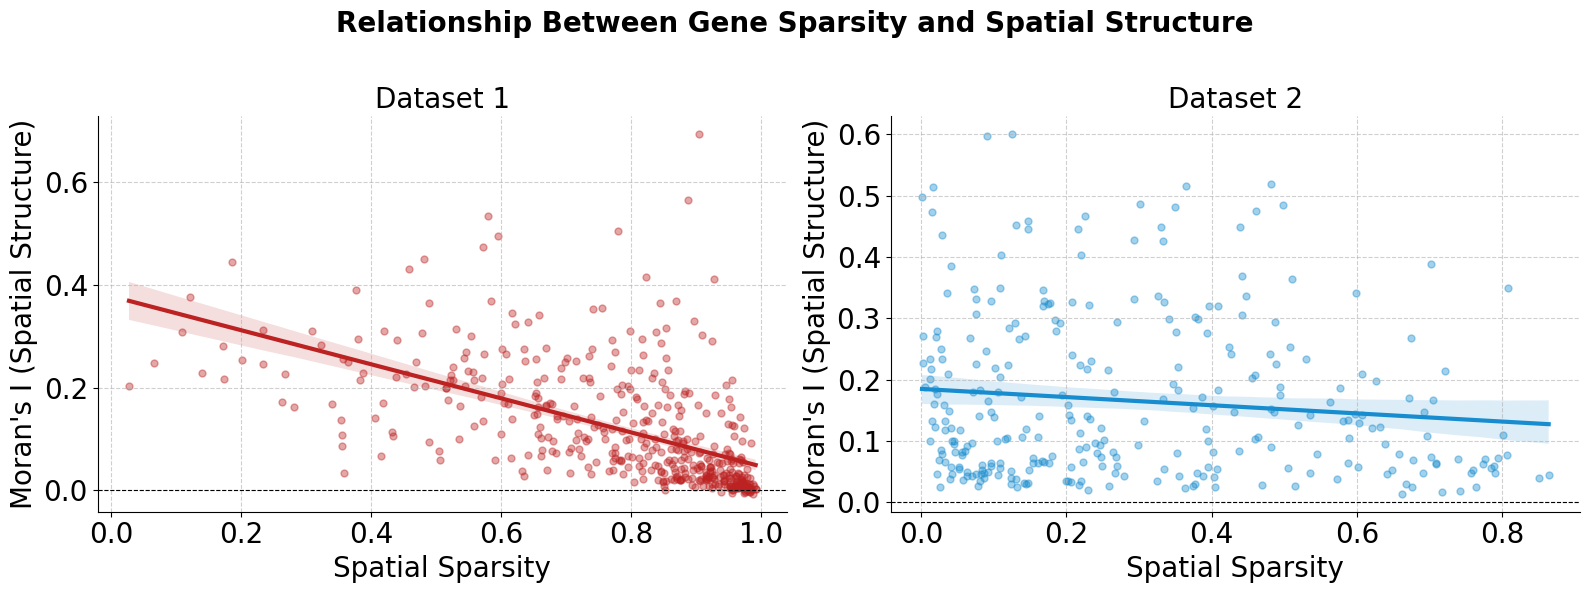

In [67]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.stats import pearsonr

# --- 1. Data Preparation ---
props_d1 = combined_df[combined_df['condition'] == 'Tangram (D1)'].dropna(subset=['moran_i', 'sparsity_sp'])
props_d2 = combined_df[combined_df['condition'] == 'Tangram (D2)'].dropna(subset=['moran_i', 'sparsity_sp'])

# --- 2. Statistical Test ---
print("--- Statistical Test of Sparsity vs. Spatial Structure ---")
r_d1, p_d1 = pearsonr(props_d1['sparsity_sp'], props_d1['moran_i'])
r_d2, p_d2 = pearsonr(props_d2['sparsity_sp'], props_d2['moran_i'])

print(f"Dataset 1: Pearson r = {r_d1:.3f}, p-value = {p_d1:.2e}")
print(f"Dataset 2: Pearson r = {r_d2:.3f}, p-value = {p_d2:.2e}")

# --- 3. Comparative Visualization ---
fig, axes = plt.subplots(1, 2, figsize=(16, 6), sharey=False)  # Removed shared y-axis, smaller height
fig.suptitle("Relationship Between Gene Sparsity and Spatial Structure", fontsize=20, weight='bold')

# Left Plot: Dataset 1
sns.regplot(data=props_d1, x='sparsity_sp', y='moran_i', ax=axes[0],
            color="#bd2222", scatter_kws={'alpha': 0.4, 's': 25}, line_kws={'linewidth': 3})
axes[0].set_title("Dataset 1", fontsize=20)
axes[0].set_xlabel("Spatial Sparsity", fontsize=20)
axes[0].set_ylabel("Moran's I (Spatial Structure)", fontsize=20)
axes[0].tick_params(labelsize=20)
axes[0].grid(True, linestyle='--', alpha=0.6)
axes[0].axhline(0, color='black', lw=0.8, linestyle='--')

# Right Plot: Dataset 2
sns.regplot(data=props_d2, x='sparsity_sp', y='moran_i', ax=axes[1],
            color="#178ccf", scatter_kws={'alpha': 0.4, 's': 25}, line_kws={'linewidth': 3})
axes[1].set_title("Dataset 2", fontsize=20)
axes[1].set_xlabel("Spatial Sparsity", fontsize=20)
axes[1].set_ylabel("Moran's I (Spatial Structure)", fontsize=20)  # Now shown separately
axes[1].tick_params(labelsize=20)
axes[1].grid(True, linestyle='--', alpha=0.6)
axes[1].axhline(0, color='black', lw=0.8, linestyle='--')

sns.despine()
plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()


Analysis of Results:
This plot is a key finding. It confirms our hypothesis with strong quantitative evidence:
Strong Positive Correlation: For both Tangram and SpaGE, there is a clear, strong positive relationship between a gene's spatial autocorrelation (Moran's I) and its imputation accuracy (Spearman's r). Genes whose expression is highly clustered (Moran's I > 0.2) are predicted with high accuracy. Genes with random or near-random spatial patterns (Moran's I near 0) are predicted poorly.
Identical Performance Profiles: The regression lines for Tangram and SpaGE are almost perfectly superimposed. This indicates that both models are equally dependent on the intrinsic spatial structure of a gene. Neither model shows a particular advantage in imputing genes with low spatial structure.
Conclusion: The "easiness" or "hardness" of imputing a gene is not an arbitrary property but is directly tied to its spatial predictability. Both models excel at reconstructing patterns that are already spatially coherent and struggle with patterns that are not.

## **4. Uncertainty Calibration and Obtaining Prediction Intervals**

In [14]:
adata_1.obsm["spatial"] = np.vstack([adata_1.obs["center_x"], adata_1.obs["center_y"]]).T
adata_2.obsm["spatial"] = np.vstack([adata_2.obs["center_x"], adata_2.obs["center_y"]]).T

### Spatial Graph Construction: `fixed_radius` Method Summary

This method builds a spatial graph by combining k-nearest neighbours (k-NN) with distance-based pruning:

1. **Build k-NN Graph**  
   - For each cell, find its `n_neighbors` (e.g. 15) closest cells using Euclidean distance.  
   - Store connections in two sparse matrices:  
     - `adata.obsp["spatial_connectivities"]`: adjacency (1s for each neighbour pair)  
     - `adata.obsp["spatial_distances"]`: distances between connected cell pairs  

2. **Calculate Distance Threshold (if `radius` is not provided)**  
   - Extract all non-zero distances.  
   - Compute `radius = Q3 + 1.5 × IQR`, where:
     - Q3 = 75th percentile  
     - IQR = Q3 - Q1  

3. **Prune Long Edges**  
   - Set values in both matrices to 0 where distances exceed `radius`.  
   - This removes spatially distant neighbours even if they were among the closest 15.

The result is a robust spatial graph that balances local neighbourhood structure with spatial coherence.


In [15]:
# build spatial graph and calculate adjacency weights

tissue.main.build_spatial_graph(adata_1, method="fixed_radius", n_neighbors=15)
tissue.main.build_spatial_graph(adata_2, method="fixed_radius", n_neighbors=15)

### Conformal Calibration: `conformalize_spatial_uncertainty` Step Summary

This method estimates uncertainty in spatial gene expression predictions using cell-centred variability and conformal prediction scores, with stratified grouping to improve calibration.

1. **Compute Spatial Uncertainty (Cell-Centred Variability)**  
   - For each cell and gene, measure how different the predicted expression is from that of neighbouring cells.  
   - Weight neighbours using either:
     - Cosine similarity of predicted expression profiles (`exp_cos`)
   - Store results as spatial standard deviations in:
     - `adata.obsm["spage_predictions_uncertainty"]`

2. **Calculate Prediction Errors and Conformal Scores**  
   - Compare predicted values to observed expression for calibration genes (all genes in this case).  
   - Compute:
     - `residual = observed − predicted`
     - `score = |residual| / uncertainty`  
   - Save results in:
     - `adata.obsm["spage_predictions_error"]`
     - `adata.obsm["spage_predictions_score"]`

3. **Group Cells for Stratified Calibration**  
   - To make uncertainty estimation more accurate, group similar gene–cell combinations together.
   - Uses a **two-level k-means clustering** approach (`grouping_method="kmeans_gene_cell"`):
     
     **Step 1: Group Genes**
     - Transpose the predicted expression matrix so each gene becomes a "sample".
     - Standardise gene vectors and optionally reduce dimensions using PCA (`n_pc`).
     - Cluster genes into `k` groups (e.g. 4) using k-means.
     - This separates genes with different expression or variability patterns.

     **Step 2: Group Cells Within Each Gene Group**
     - For each gene cluster, take the submatrix (cells × selected genes).
     - Standardise, optionally run PCA (`n_pc2`), and cluster the cells into `k2` groups (e.g. 2).
     - This allows cells to be grouped **in a gene-context-aware way**, so uncertainty scores reflect local structure.

   - Each cell–gene pair is then assigned a **stratified group ID** (e.g. Group 0, 1, ..., N).
   - These groupings are used to calculate separate conformal score distributions for each group, improving calibration for diverse expression patterns.

   - **Stores results in:**
     - `adata.obsm["spage_predictions_groups"]` → a matrix of group labels (cells × genes)
     - `adata.uns["spage_predictions_kg"]` and `..._kc` → stores the number of gene and cell clusters used


4. **Prepare for Stratified Conformal Prediction**  
   - These scores and groupings are used in downstream steps to assign cell-specific, gene-specific prediction intervals.
   - This allows uncertainty estimates to adapt to both spatial and biological context.

The result is a calibrated, spatially-aware uncertainty measure for each predicted gene expression value.


In [36]:
# build calibration scores

tissue.main.conformalize_spatial_uncertainty(adata_1, "spage_predictions", calib_genes=adata_1.var_names,
                                             grouping_method="kmeans_gene_cell", k=4, k2=2)

/Users/Amith/miniconda3/envs/tissue/lib/python3.8/site-packages/threadpoolctl.py:1214: RuntimeWarning: 
Found Intel OpenMP ('libiomp') and LLVM OpenMP ('libomp') loaded at
the same time. Both libraries are known to be incompatible and this
can cause random crashes or deadlocks on Linux when loaded in the
same Python program.
Using threadpoolctl may cause crashes or deadlocks. For more
information and possible workarounds, please see
    https://github.com/joblib/threadpoolctl/blob/master/multiple_openmp.md

  warnings.warn(msg, RuntimeWarning)


In [37]:
# build calibration scores

tissue.main.conformalize_spatial_uncertainty(adata_1, "tangram_predictions", calib_genes=adata_1.var_names,
                                             grouping_method="kmeans_gene_cell", k=4, k2=2)

In [16]:
# build calibration scores

tissue.main.conformalize_spatial_uncertainty(adata_2, "spage_predictions", calib_genes=adata_2.var_names,
                                             grouping_method="kmeans_gene_cell", k=4, k2=2)

/Users/Amith/miniconda3/envs/tissue/lib/python3.8/site-packages/threadpoolctl.py:1214: RuntimeWarning: 
Found Intel OpenMP ('libiomp') and LLVM OpenMP ('libomp') loaded at
the same time. Both libraries are known to be incompatible and this
can cause random crashes or deadlocks on Linux when loaded in the
same Python program.
Using threadpoolctl may cause crashes or deadlocks. For more
information and possible workarounds, please see
    https://github.com/joblib/threadpoolctl/blob/master/multiple_openmp.md

  warnings.warn(msg, RuntimeWarning)


In [17]:
# build calibration scores

tissue.main.conformalize_spatial_uncertainty(adata_2, "tangram_predictions", calib_genes=adata_2.var_names,
                                             grouping_method="kmeans_gene_cell", k=4, k2=2)

### Prediction Interval Conformalisation

In [38]:
tissue.main.conformalize_prediction_interval (adata_1, "spage_predictions", symmetric=False, calib_genes=adata_1.var_names,
                                              alpha_level=0.23)

In [39]:
tissue.main.conformalize_prediction_interval (adata_1, "tangram_predictions", symmetric=False, calib_genes=adata_1.var_names,
                                              alpha_level=0.23)

In [18]:
tissue.main.conformalize_prediction_interval (adata_2, "spage_predictions", symmetric=False, calib_genes=adata_2.var_names,
                                              alpha_level=0.23)

In [19]:
tissue.main.conformalize_prediction_interval (adata_2, "tangram_predictions", symmetric=False, calib_genes=adata_2.var_names,
                                              alpha_level=0.23)

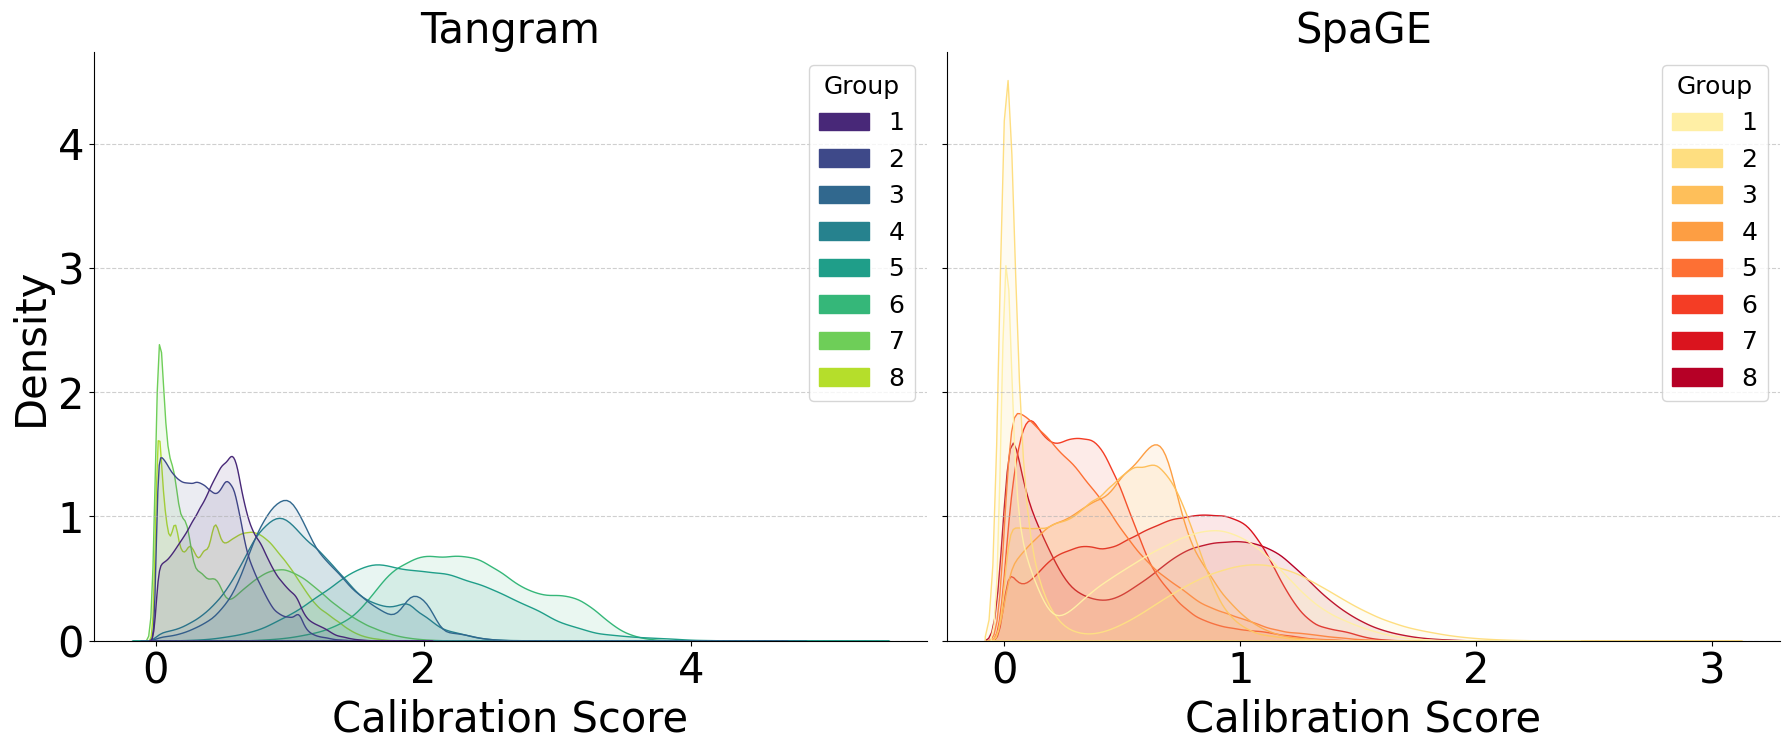

In [85]:
# -------------------------------------------------------------------------
# 0. Imports
# -------------------------------------------------------------------------
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

# -------------------------------------------------------------------------
# 1. Function to prepare calibration data for plotting
# -------------------------------------------------------------------------
def prepare_calibration_data(adata, model_name):
    pred_key  = model_name
    score_key = f"{pred_key}_score"
    group_key = f"{pred_key}_groups"

    if score_key not in adata.obsm or group_key not in adata.obsm:
        print(f"Warning: Data not found for '{pred_key}'. Skipping.")
        return None

    scores_obj = adata.obsm[score_key]
    groups_obj = adata.obsm[group_key]

    scores = scores_obj.values.flatten() if hasattr(scores_obj, "values") else scores_obj.flatten()
    groups = groups_obj.values.flatten() if hasattr(groups_obj, "values") else groups_obj.flatten()

    df = pd.DataFrame({"calibration_score": scores,
                       "group": groups}).dropna()
    df["group"] = df["group"].astype(int).astype("category")
    return df

# -------------------------------------------------------------------------
# 2. Prepare data for both models
# -------------------------------------------------------------------------
try:
    tg_plot_df = prepare_calibration_data(adata_2, "tangram_predictions")
    sp_plot_df = prepare_calibration_data(adata_2, "spage_predictions")
except NameError:
    raise RuntimeError("FATAL: AnnData object 'adata_2' not found.")

# -------------------------------------------------------------------------
# 3. 1×2 KDE figure
# -------------------------------------------------------------------------
if tg_plot_df is None or sp_plot_df is None:
    print("Could not generate plots due to missing data.")
else:
    group_order = sorted(set(tg_plot_df["group"]).union(sp_plot_df["group"]))
    tg_palette  = sns.color_palette("viridis", n_colors=len(group_order))
    sp_palette  = sns.color_palette("YlOrRd",  n_colors=len(group_order))

    fig, axes = plt.subplots(1, 2, figsize=(18, 8), sharey=True)

    # Tangram --------------------------------------------------------------
    sns.kdeplot(data=tg_plot_df, x="calibration_score",
                hue="group", hue_order=group_order, palette=tg_palette,
                common_norm=False, fill=True, alpha=0.10,
                ax=axes[0], legend=False)
    axes[0].set_title("Tangram", fontsize=30)
    axes[0].set_xlabel("Calibration Score", fontsize=30)
    axes[0].set_ylabel("Density",            fontsize=30)
    axes[0].tick_params(labelsize=30)

    # SpaGE ---------------------------------------------------------------
    sns.kdeplot(data=sp_plot_df, x="calibration_score",
                hue="group", hue_order=group_order, palette=sp_palette,
                common_norm=False, fill=True, alpha=0.10,
                ax=axes[1], legend=False)
    axes[1].set_title("SpaGE", fontsize=30)
    axes[1].set_xlabel("Calibration Score", fontsize=30)
    axes[1].set_ylabel("")                   # shared Y
    axes[1].tick_params(labelsize=30)

    # Legends (now 18 pt) --------------------------------------------------
    def build_handles(pal):
        return [Patch(color=pal[i], label=f"{i+1}") for i in range(len(group_order))]

    axes[0].legend(handles=build_handles(tg_palette), title="Group",
                   title_fontsize=18, fontsize=18)
    axes[1].legend(handles=build_handles(sp_palette), title="Group",
                   title_fontsize=18, fontsize=18)

    # Grid / tidy ----------------------------------------------------------
    for ax in axes:
        ax.grid(axis="y", linestyle="--", alpha=0.6)

    sns.despine()
    plt.tight_layout(rect=[0, 0, 1, 0.95])
    plt.show()



--- Uncertainty Reliability Analysis for Dataset 2 ---

--- Summary of Reliability Scores (Mean ± Std Dev) ---
          mean    std
model                
SpaGE    0.129  0.153
Tangram  0.122  0.130

--- Statistical Test: Tangram vs. SpaGE (Paired) ---
W-statistic: 20593.0, p-value: 3.474e-01
Conclusion: No significant difference


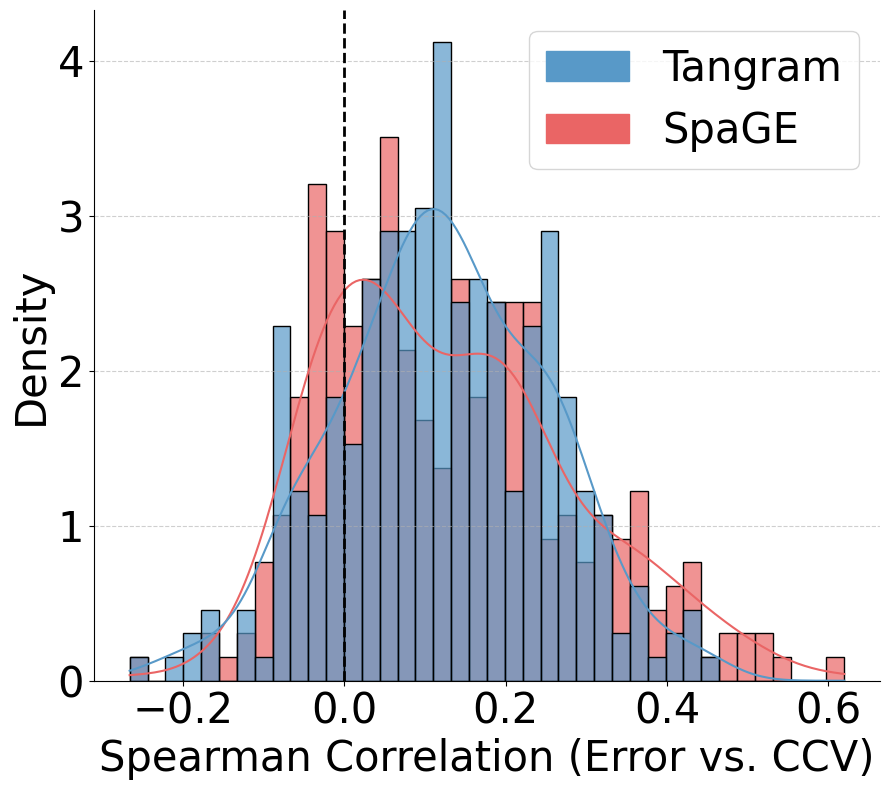

In [86]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.stats import spearmanr, wilcoxon
from tqdm.auto import tqdm

# --- 1. Function to Calculate RELIABILITY OF CELL-CENTRIC VARIABILITY ---
def calculate_variability_correlations(adata, dataset_name):
    """Calculates per-gene Spearman correlation between absolute error and CELL-CENTRIC VARIABILITY."""
    models_to_test = {'Tangram': 'tangram_predictions', 'SpaGE': 'spage_predictions'}
    results_list = []
    for model_name, pred_key in models_to_test.items():
        error_key, uncertainty_key = f"{pred_key}_error", f"{pred_key}_uncertainty"
        if not all(k in adata.obsm for k in [error_key, uncertainty_key]):
            continue
        gene_iterator = tqdm(adata.var_names, desc=f"Processing {model_name} ({dataset_name})", leave=False)
        for gene in gene_iterator:
            abs_error = np.abs(adata.obsm[error_key][gene].values)
            variability = adata.obsm[uncertainty_key][gene].values
            corr, _ = spearmanr(abs_error, variability)
            results_list.append({'correlation': corr, 'model': model_name})
    return pd.DataFrame(results_list)

# --- 2. Run for Dataset 2 ONLY ---
try:
    corr_d2_df = calculate_variability_correlations(adata_2, "D2")
except NameError:
    print("FATAL ERROR: AnnData object 'adata_2' not found."); exit()

# --- 3. Statistical Summaries and Tests for Dataset 2 ---
print("--- Uncertainty Reliability Analysis for Dataset 2 ---")

# Descriptive Statistics
print("\n--- Summary of Reliability Scores (Mean ± Std Dev) ---")
summary_stats = corr_d2_df.groupby('model')['correlation'].agg(['mean', 'std'])
print(summary_stats.round(3))

# Paired Statistical Test (Wilcoxon)
print("\n--- Statistical Test: Tangram vs. SpaGE (Paired) ---")
tg_scores = corr_d2_df[corr_d2_df['model'] == 'Tangram']['correlation'].dropna()
sp_scores = corr_d2_df[corr_d2_df['model'] == 'SpaGE']['correlation'].dropna()

w_stat, p_val = wilcoxon(tg_scores, sp_scores)

if p_val < 0.05:
    median_tg, median_sp = tg_scores.median(), sp_scores.median()
    direction = "Tangram > SpaGE" if median_tg > median_sp else "SpaGE > Tangram"
    conclusion = f"Significant ({direction})"
else:
    conclusion = "No significant difference"

print(f"W-statistic: {w_stat:.1f}, p-value: {p_val:.3e}")
print(f"Conclusion: {conclusion}")


# --- 4. Final Visualization for Dataset 2 ---
plt.figure(figsize=(9, 8))
ax = plt.gca()
custom_palette = {'Tangram': "#5899C8", 'SpaGE': "#EA6565"}
hue_order = ['Tangram', 'SpaGE']

sns.histplot(data=corr_d2_df, x='correlation', hue='model', bins=40, stat='density', 
             common_norm=False, palette=custom_palette, hue_order=hue_order, 
             alpha=0.7, kde=True, ax=ax)

# ax.set_title("Distribution of Variability Reliability Scores (Dataset 2)", fontsize=20, weight='bold')
ax.set_xlabel("Spearman Correlation (Error vs. CCV)", fontsize=30)
ax.set_ylabel("Density", fontsize=30)
ax.tick_params(labelsize=30)
ax.grid(axis='y', linestyle='--', alpha=0.6)
ax.axvline(x=0, color='black', linestyle='--', linewidth=2)

from matplotlib.patches import Patch
handles = [Patch(color=custom_palette[model], label=model) for model in hue_order]
ax.legend(handles=handles, fontsize=30)

sns.despine()
plt.tight_layout()
plt.show()

#END

--- Prediction Interval (PI) Reliability Analysis for Dataset 2 ---

--- Summary of PI Reliability Scores (Mean ± Std Dev) ---
          mean    std
model                
SpaGE    0.063  0.167
Tangram  0.108  0.213

--- Statistical Test: Tangram vs. SpaGE (Paired) ---
W-statistic: 17021.0, p-value: 7.700e-04
Conclusion: Significant (Tangram > SpaGE)


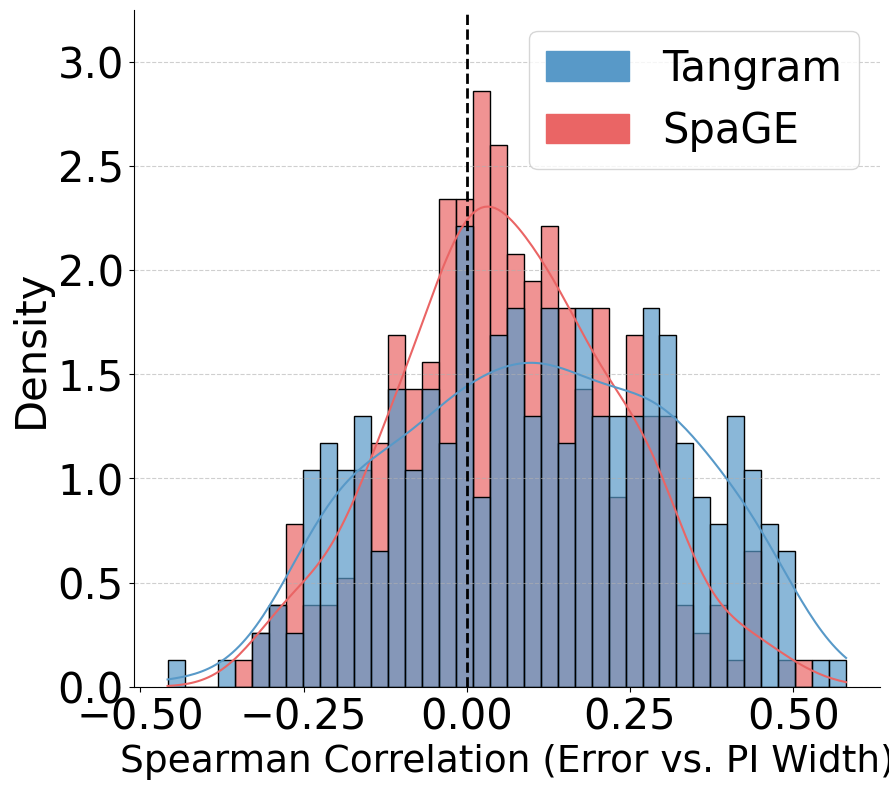

In [90]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.stats import spearmanr, wilcoxon
from tqdm.auto import tqdm

# --- 1. Function to Calculate RELIABILITY OF PREDICTION INTERVALS ---
def calculate_pi_width_correlations(adata, dataset_name):
    """Calculates per-gene Spearman correlation between absolute error and PI WIDTH."""
    models_to_test = {'Tangram': 'tangram_predictions', 'SpaGE': 'spage_predictions'}
    results_list = []
    for model_name, pred_key in models_to_test.items():
        error_key, lo_key, hi_key = f"{pred_key}_error", f"{pred_key}_lo", f"{pred_key}_hi"
        if not all(k in adata.obsm for k in [error_key, lo_key, hi_key]):
            continue
        gene_iterator = tqdm(adata.var_names, desc=f"Processing {model_name} ({dataset_name})", leave=False)
        for gene in gene_iterator:
            abs_error = np.abs(adata.obsm[error_key][gene].values)
            pi_width = adata.obsm[hi_key][gene].values - adata.obsm[lo_key][gene].values
            corr, _ = spearmanr(abs_error, pi_width)
            results_list.append({'correlation': corr, 'model': model_name})
    return pd.DataFrame(results_list)

# --- 2. Run for Dataset 2 ONLY ---
try:
    corr_d2_df_pi = calculate_pi_width_correlations(adata_2, "D2")
except NameError:
    print("FATAL ERROR: AnnData object 'adata_2' not found."); exit()

# --- 3. Statistical Summaries and Tests for Dataset 2 ---
print("--- Prediction Interval (PI) Reliability Analysis for Dataset 2 ---")

# Descriptive Statistics
print("\n--- Summary of PI Reliability Scores (Mean ± Std Dev) ---")
summary_stats_pi = corr_d2_df_pi.groupby('model')['correlation'].agg(['mean', 'std'])
print(summary_stats_pi.round(3))

# Paired Statistical Test (Wilcoxon)
print("\n--- Statistical Test: Tangram vs. SpaGE (Paired) ---")
tg_scores_pi = corr_d2_df_pi[corr_d2_df_pi['model'] == 'Tangram']['correlation'].dropna()
sp_scores_pi = corr_d2_df_pi[corr_d2_df_pi['model'] == 'SpaGE']['correlation'].dropna()

w_stat_pi, p_val_pi = wilcoxon(tg_scores_pi, sp_scores_pi)

if p_val_pi < 0.05:
    median_tg, median_sp = tg_scores_pi.median(), sp_scores_pi.median()
    direction = "Tangram > SpaGE" if median_tg > median_sp else "SpaGE > Tangram"
    conclusion = f"Significant ({direction})"
else:
    conclusion = "No significant difference"

print(f"W-statistic: {w_stat_pi:.1f}, p-value: {p_val_pi:.3e}")
print(f"Conclusion: {conclusion}")

# --- 4. Final Visualization for Dataset 2 ---
plt.figure(figsize=(9, 8))
ax = plt.gca()
custom_palette = {'Tangram': "#5899C8", 'SpaGE': "#EA6565"}
hue_order = ['Tangram', 'SpaGE']

sns.histplot(data=corr_d2_df_pi, x='correlation', hue='model', bins=40, stat='density', 
             common_norm=False, palette=custom_palette, hue_order=hue_order, 
             alpha=0.7, kde=True, ax=ax)

# ax.set_title("Distribution of PI Reliability Scores (Dataset 2)", fontsize=30, weight='bold')
ax.set_xlabel("Spearman Correlation (Error vs. PI Width)", fontsize=27)
ax.set_ylabel("Density", fontsize=30)
ax.set_ylim(0,3.25)
ax.tick_params(labelsize=30)
ax.grid(axis='y', linestyle='--', alpha=0.6)
ax.axvline(x=0, color='black', linestyle='--', linewidth=2)

from matplotlib.patches import Patch
handles = [Patch(color=custom_palette[model], label=model) for model in hue_order]
ax.legend(handles=handles, fontsize=30)

sns.despine()
plt.tight_layout()
plt.show()

#END


Tangram | Dataset 2
Trend (Spearman)  Moran’s I  r=0.036  p=0.536
Trend (Spearman)  Sparsity  r=-0.500  p=4.02e-20
Mann-Whitney U     Moran’s I  p=0.465
Mann-Whitney U     Sparsity  p=4.28e-13


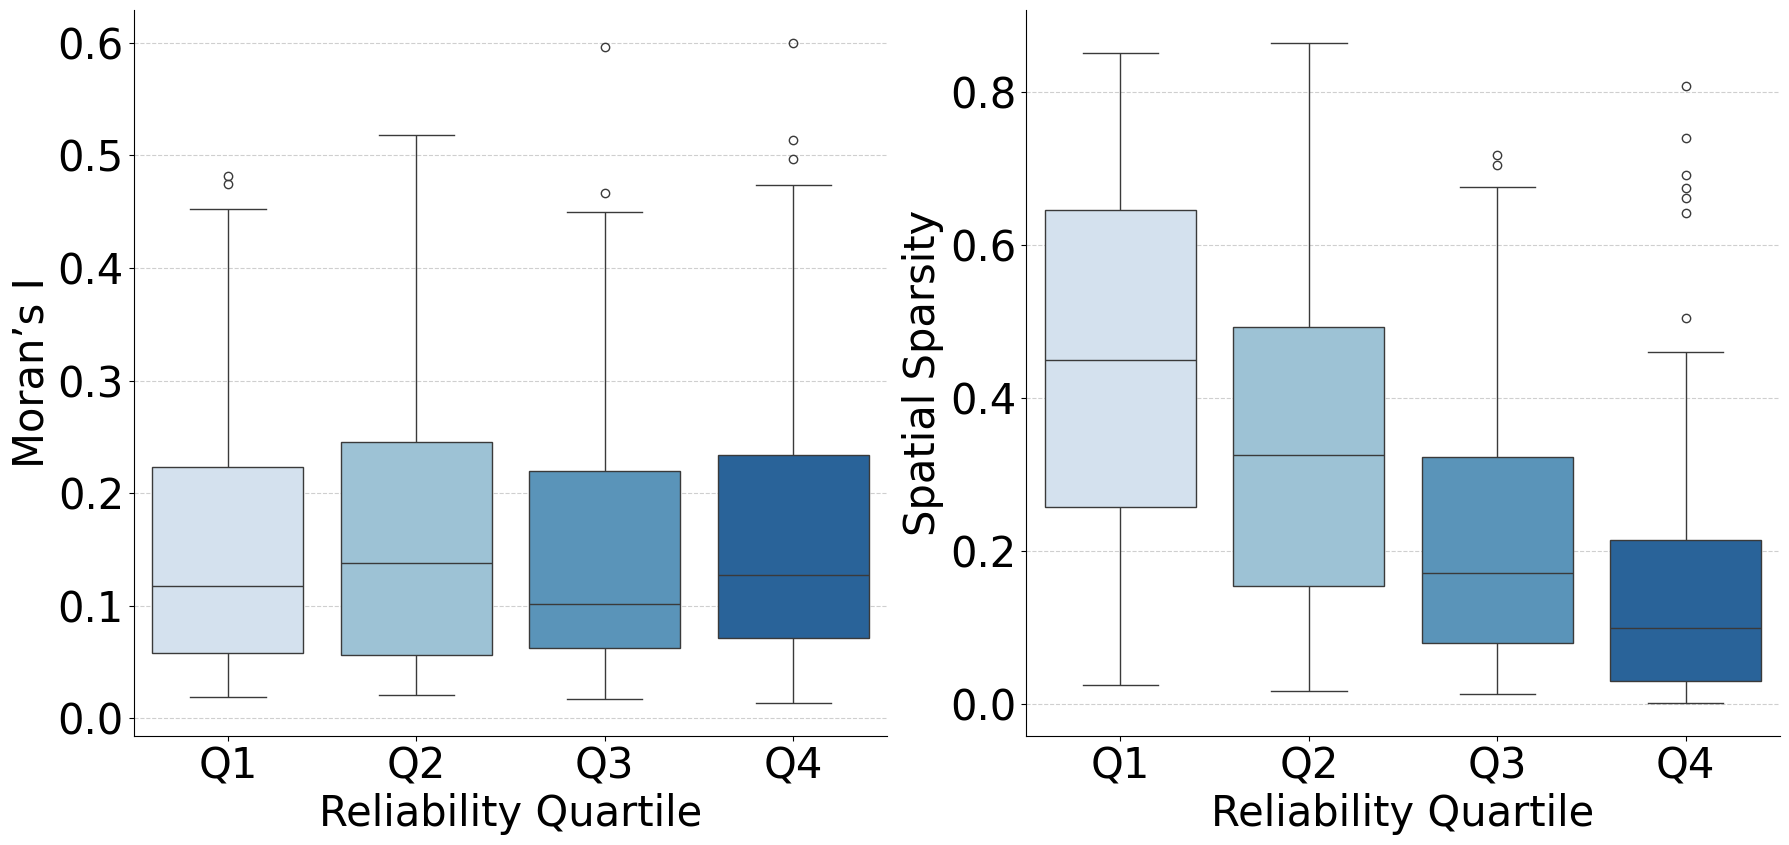


SpaGE | Dataset 2
Trend (Spearman)  Moran’s I  r=0.248  p=1.62e-05
Trend (Spearman)  Sparsity  r=-0.390  p=3.36e-12
Mann-Whitney U     Moran’s I  p=4.63e-06
Mann-Whitney U     Sparsity  p=4.27e-09


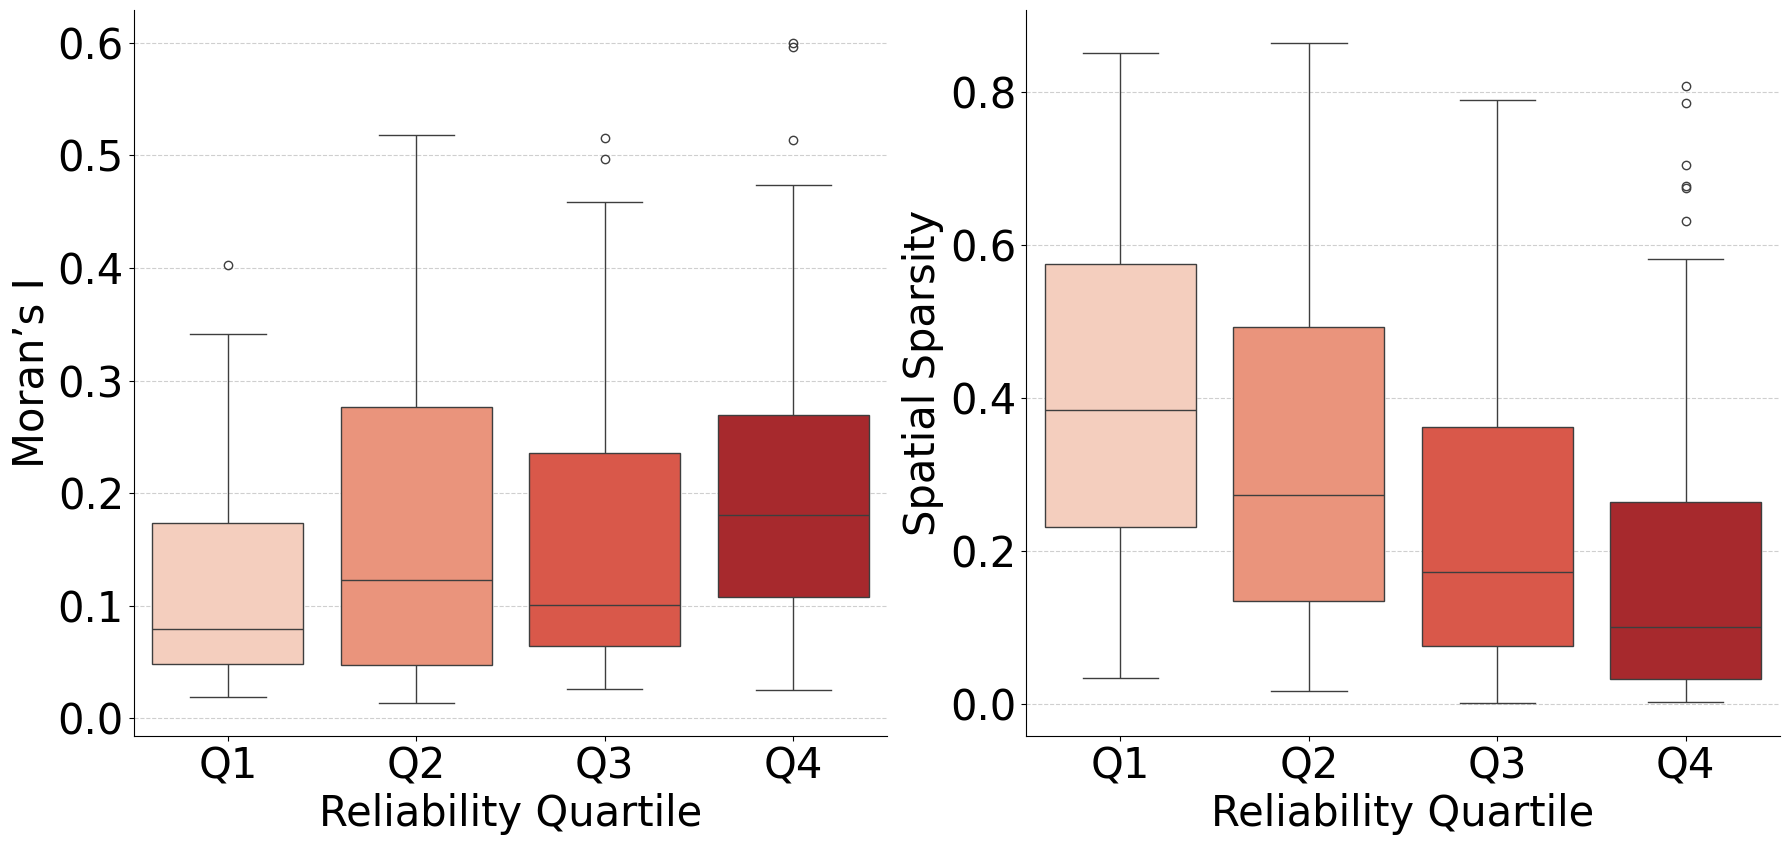

In [91]:
# -------------------------------------------------------------------------
# 0. Imports
# -------------------------------------------------------------------------
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.stats import mannwhitneyu, spearmanr
from matplotlib.patches import Patch

# -------------------------------------------------------------------------
# 1. Function: tidy calibration data
# -------------------------------------------------------------------------
def prepare_calibration_data(adata, model_name):
    score_key  = f"{model_name}_score"
    group_key  = f"{model_name}_groups"
    if score_key not in adata.obsm or group_key not in adata.obsm:
        print(f"Warning: '{model_name}' keys missing — skipped.")
        return None

    # handle DataFrame / ndarray
    scores = adata.obsm[score_key]
    groups = adata.obsm[group_key]
    scores = scores.values.flatten() if hasattr(scores, "values") else scores.flatten()
    groups = groups.values.flatten() if hasattr(groups, "values") else groups.flatten()

    df = pd.DataFrame({"calibration_score": scores, "group": groups}).dropna()
    df["group"] = df["group"].astype(int).astype("category")
    return df

# -------------------------------------------------------------------------
# 2. Prepare data for Dataset-2
# -------------------------------------------------------------------------
try:
    tg_d2_reliability = corr_d2_df_pi[corr_d2_df_pi["model"] == "Tangram"].copy()
    sp_d2_reliability = corr_d2_df_pi[corr_d2_df_pi["model"] == "SpaGE"].copy()
    props_d2 = (
        combined_df[combined_df["dataset"] == "D2"]
        .loc[lambda df: ~df.index.duplicated(keep="first")]
    )
    tg_d2_reliability["gene"] = tangram_gene_metrics_d2.index
    sp_d2_reliability["gene"] = spage_gene_metrics_d2.index

    analysis_tg = pd.merge(tg_d2_reliability, props_d2,
                           left_on="gene", right_index=True)
    analysis_sp = pd.merge(sp_d2_reliability, props_d2,
                           left_on="gene", right_index=True)
except NameError as e:
    raise RuntimeError(f"FATAL: prerequisite DataFrames missing – {e}")

# -------------------------------------------------------------------------
# 3. Analysis + plotting helper
# -------------------------------------------------------------------------
def run_quartile_analysis(df, model_name):
    df = df.copy()
    df["reliability_quartile"] = pd.qcut(
        df["correlation"],
        q=4,
        labels=["Q1", "Q2", "Q3", "Q4"]
    )
    df["quartile_numeric"] = df["reliability_quartile"].cat.codes
    order = ["Q1", "Q2", "Q3", "Q4"]

    # ---------- stats ----------
    print(f"\n{'='*80}\n{model_name} | Dataset 2\n{'='*80}")
    r_mor, p_mor = spearmanr(df["quartile_numeric"], df["moran_i"].fillna(0))
    r_spa, p_spa = spearmanr(df["quartile_numeric"], df["sparsity_sp"])
    print(f"Trend (Spearman)  Moran’s I  r={r_mor:.3f}  p={p_mor:.3g}")
    print(f"Trend (Spearman)  Sparsity  r={r_spa:.3f}  p={p_spa:.3g}")
    q1, q4 = df[df["reliability_quartile"] == "Q1"], df[df["reliability_quartile"] == "Q4"]
    p_mwu_mor = mannwhitneyu(q1["moran_i"], q4["moran_i"]).pvalue
    p_mwu_spa = mannwhitneyu(q1["sparsity_sp"], q4["sparsity_sp"]).pvalue
    print(f"Mann-Whitney U     Moran’s I  p={p_mwu_mor:.3g}")
    print(f"Mann-Whitney U     Sparsity  p={p_mwu_spa:.3g}")

    # ---------- palettes ----------
    palette_name = "Blues" if model_name.lower().startswith("tangram") else "Reds"
    palette = sns.color_palette(palette_name, n_colors=len(order))
    palette_dict = dict(zip(order, palette))

    # ---------- figure ----------
    fig, axes = plt.subplots(1, 2, figsize=(18, 9))
    # fig.suptitle(f"Gene Properties vs. Reliability Quartiles — {model_name}",
    #              fontsize=20, weight="bold")

    sns.boxplot(data=df, x="reliability_quartile", y="moran_i",
                order=order, palette=palette_dict, ax=axes[0])
    # axes[0].set_title("Spatial Structure (Moran’s I)",  fontsize=20)
    axes[0].set_xlabel("Reliability Quartile",          fontsize=30)
    axes[0].set_ylabel("Moran’s I",                     fontsize=30)

    sns.boxplot(data=df, x="reliability_quartile", y="sparsity_sp",
                order=order, palette=palette_dict, ax=axes[1])
    # axes[1].set_title("Spatial Sparsity",               fontsize=20)
    axes[1].set_xlabel("Reliability Quartile",          fontsize=30)
    axes[1].set_ylabel("Spatial Sparsity",                 fontsize=30)

    for ax in axes:
        ax.tick_params(axis="both", labelsize=30)
        ax.grid(axis="y", linestyle="--", alpha=0.6)

    sns.despine()
    plt.tight_layout(rect=[0, 0, 1, 0.95])
    plt.show()

# -------------------------------------------------------------------------
# 4. Run for each model
# -------------------------------------------------------------------------
run_quartile_analysis(analysis_tg, "Tangram")
run_quartile_analysis(analysis_sp, "SpaGE")


--- Case Study Genes: Reliable vs. Unreliable Uncertainty (SpaGE, D2) ---

--- Top 3 Most Reliable (SpaGE) ---
     gene  correlation
471  plp1        0.519

--- Top 3 Most Unreliable (SpaGE) ---
        gene  correlation
559  tmem59l       -0.331


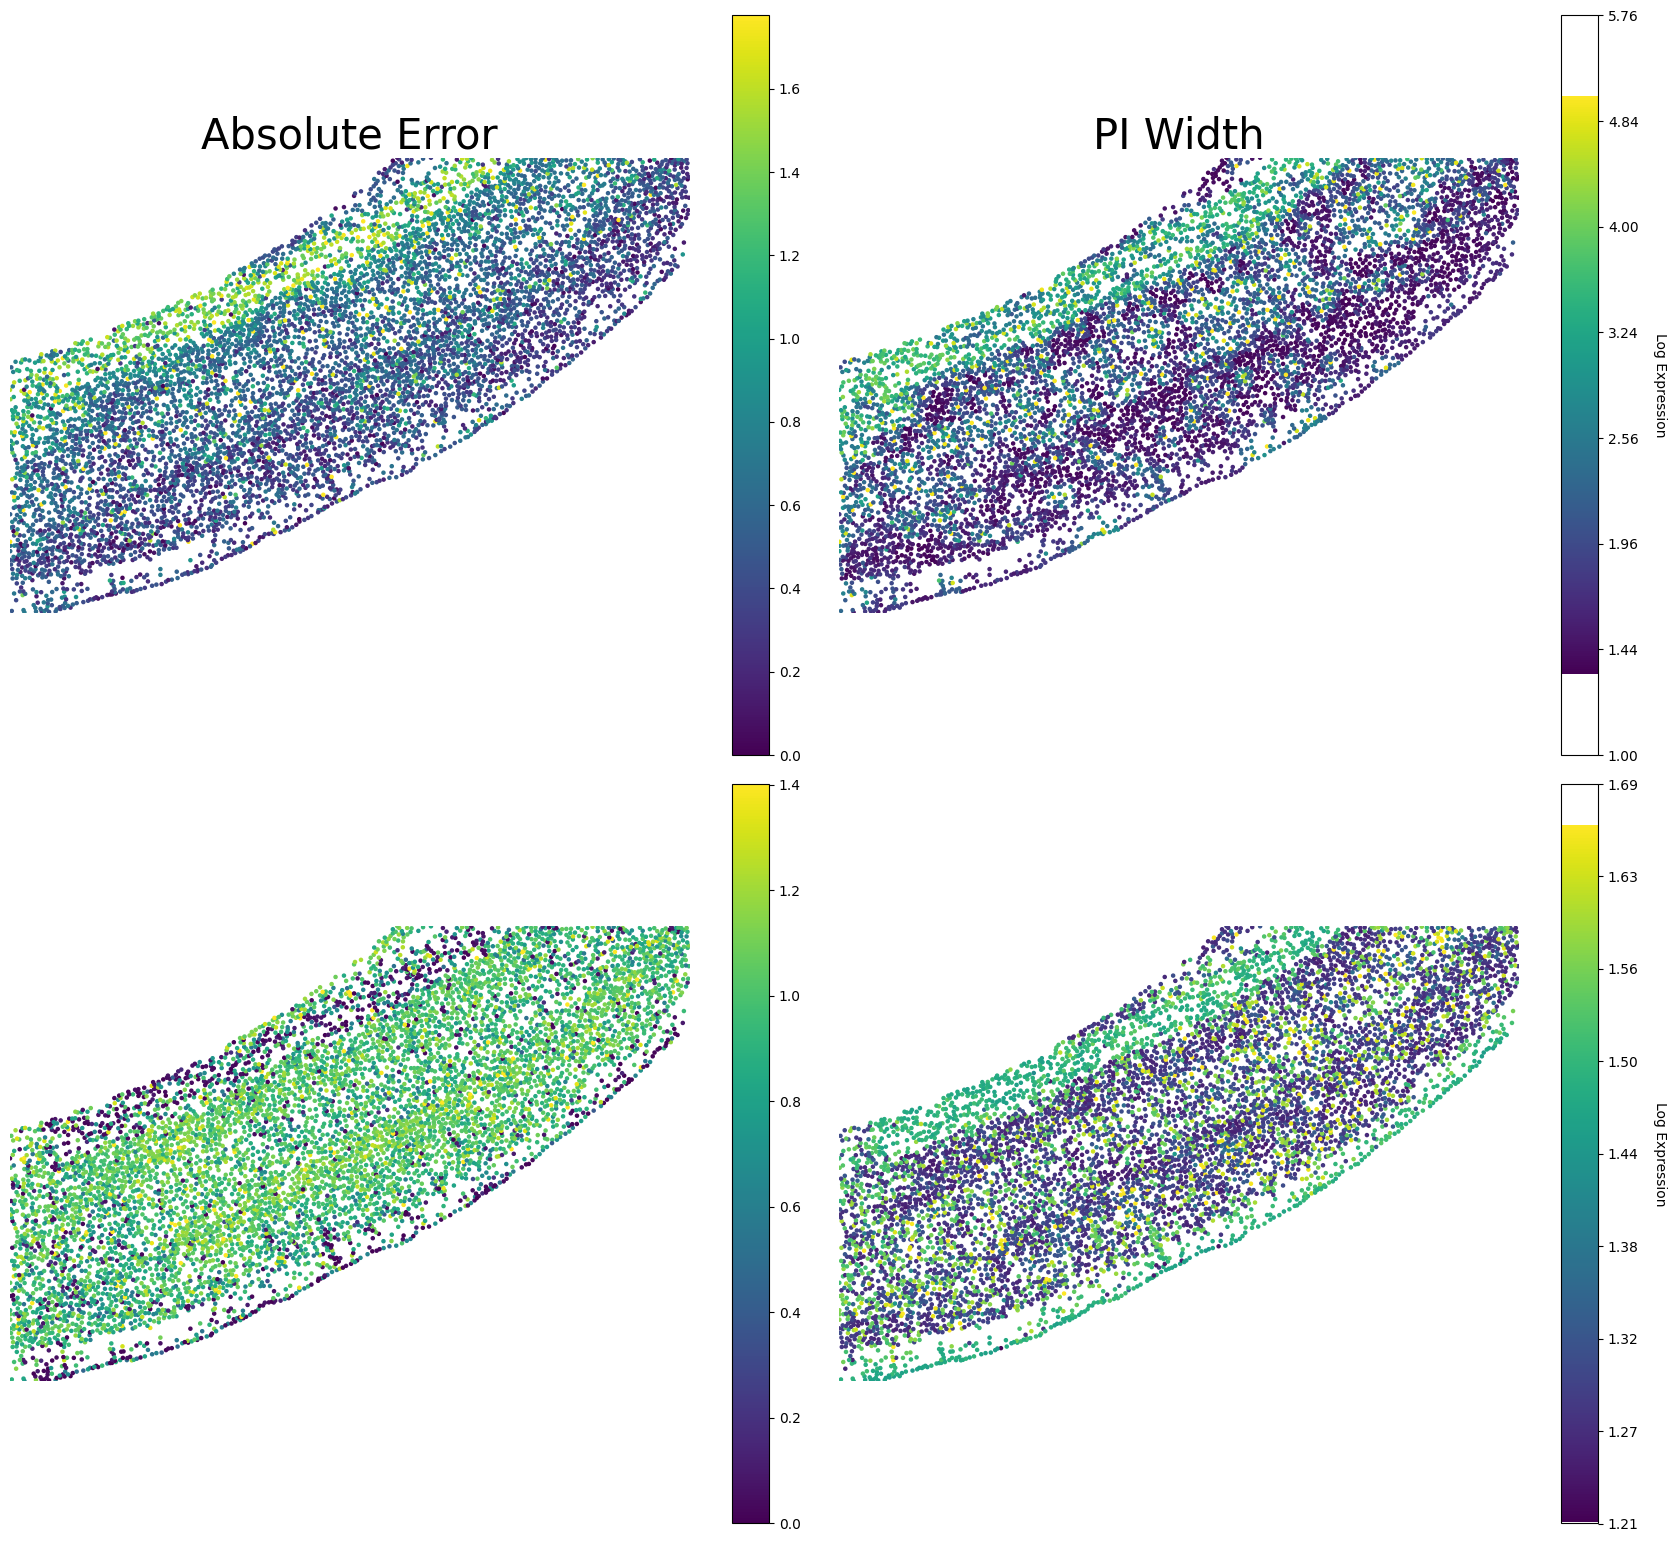

In [93]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

# --- 1. Identify Genes to Plot (SpaGE, D2) ---
# This part remains the same.
try:
    sp_d2_reliability = corr_d2_df_pi[corr_d2_df_pi['model'] == 'SpaGE'].copy()
    sp_d2_reliability['gene'] = spage_gene_metrics_d2.index
    sp_d2_reliability_sorted = sp_d2_reliability.sort_values('correlation', ascending=False)
    
    reliable_genes = sp_d2_reliability_sorted.head(1)
    unreliable_genes = sp_d2_reliability_sorted.tail(1)
    genes_to_plot = pd.concat([reliable_genes, unreliable_genes])
except NameError as e:
    print(f"FATAL ERROR: Prerequisite DataFrames not found. Error: {e}"); exit()

# --- 2. Textual Summary ---
print("--- Case Study Genes: Reliable vs. Unreliable Uncertainty (SpaGE, D2) ---")
print("\n--- Top 3 Most Reliable (SpaGE) ---"); print(reliable_genes[['gene', 'correlation']].round(3))
print("\n--- Top 3 Most Unreliable (SpaGE) ---"); print(unreliable_genes[['gene', 'correlation']].round(3))


# --- 3. Generate the ZOOMED Visualization with Enhanced Contrast ---
n_genes = len(genes_to_plot)
fig, axes = plt.subplots(n_genes, 2, figsize=(18, 8 * n_genes), squeeze=False)
# fig.suptitle("Zoomed Case Studies: Reliability of Prediction Intervals (SpaGE, D2)", fontsize=22, weight='bold')
coords = adata_2.obsm['spatial']

xlim = (6000, 8500); ylim = (325, 2000)

for i, (idx, gene_info) in enumerate(genes_to_plot.iterrows()):
    gene_name, corr_score = gene_info['gene'], gene_info['correlation']
    row_label = "Reliable" if i < 3 else "Unreliable"
    
    error = np.abs(adata_2.obsm['spage_predictions_error'][gene_name].values)
    pi_width = (adata_2.obsm['spage_predictions_hi'][gene_name].values - 
                adata_2.obsm['spage_predictions_lo'][gene_name].values).clip(min=0)

    zoom_mask = (coords[:, 0] >= xlim[0]) & (coords[:, 0] <= xlim[1]) & \
                (coords[:, 1] >= ylim[0]) & (coords[:, 1] <= ylim[1])
    
    coords_zoom, error_zoom, pi_width_zoom = coords[zoom_mask], error[zoom_mask], pi_width[zoom_mask]

    # Shared vmin/vmax for the 'Absolute Error' plot in the row
    err_vmin, err_vmax = np.min(error_zoom), np.percentile(error_zoom, 99)

    # axes[i, 0].set_ylabel(f"{row_label}\n{gene_name}\n(R={corr_score:.2f})", fontsize=14, weight='bold', labelpad=30, rotation=0, ha='right')

    # Plot Absolute Error (Linear Scale)
    im_err = axes[i, 0].scatter(coords_zoom[:, 0], coords_zoom[:, 1], c=error_zoom, cmap='viridis', s=5, vmin=err_vmin, vmax=err_vmax, rasterized=True)
    fig.colorbar(im_err, ax=axes[i, 0])

    # --- ENHANCED CONTRAST PLOTTING FOR PI WIDTH ---
    # Apply a power-law transformation (sqrt) to enhance contrast for low values
    power = 0.5 
    pi_width_transformed = np.power(pi_width_zoom, power)
    
    # Calculate vmin/vmax on the transformed data
    pi_vmin_t, pi_vmax_t = np.min(pi_width_transformed), np.percentile(pi_width_transformed, 99)
    
    # Plot the transformed data
    im_pi = axes[i, 1].scatter(coords_zoom[:, 0], coords_zoom[:, 1], c=pi_width_transformed, cmap='viridis', s=5, vmin=pi_vmin_t, vmax=pi_vmax_t, rasterized=True)
    
    # Create and label the colorbar to reflect the original, untransformed scale
    cbar = fig.colorbar(im_pi, ax=axes[i, 1])
    # Get the tick locations on the transformed scale
    tick_locs = cbar.get_ticks()
    # Create new labels by "un-transforming" the tick locations
    tick_labels = [f"{val**(1/power):.2f}" for val in tick_locs]
    cbar.set_ticks(tick_locs)
    cbar.set_ticklabels(tick_labels)
    cbar.set_label("Log Expression", rotation=270, labelpad=20)


    if i == 0:
        axes[i, 0].set_title("Absolute Error", fontsize=30)
        axes[i, 1].set_title("PI Width", fontsize=30)

for ax in axes.flatten():
    ax.set_aspect('equal', adjustable='box'); ax.set_xticks([]); ax.set_yticks([])
    ax.set_xlim(xlim); ax.set_ylim(ylim)

sns.despine(left=True, bottom=True)
plt.tight_layout(rect=[0.05, 0, 1, 0.97])
plt.show()

#END

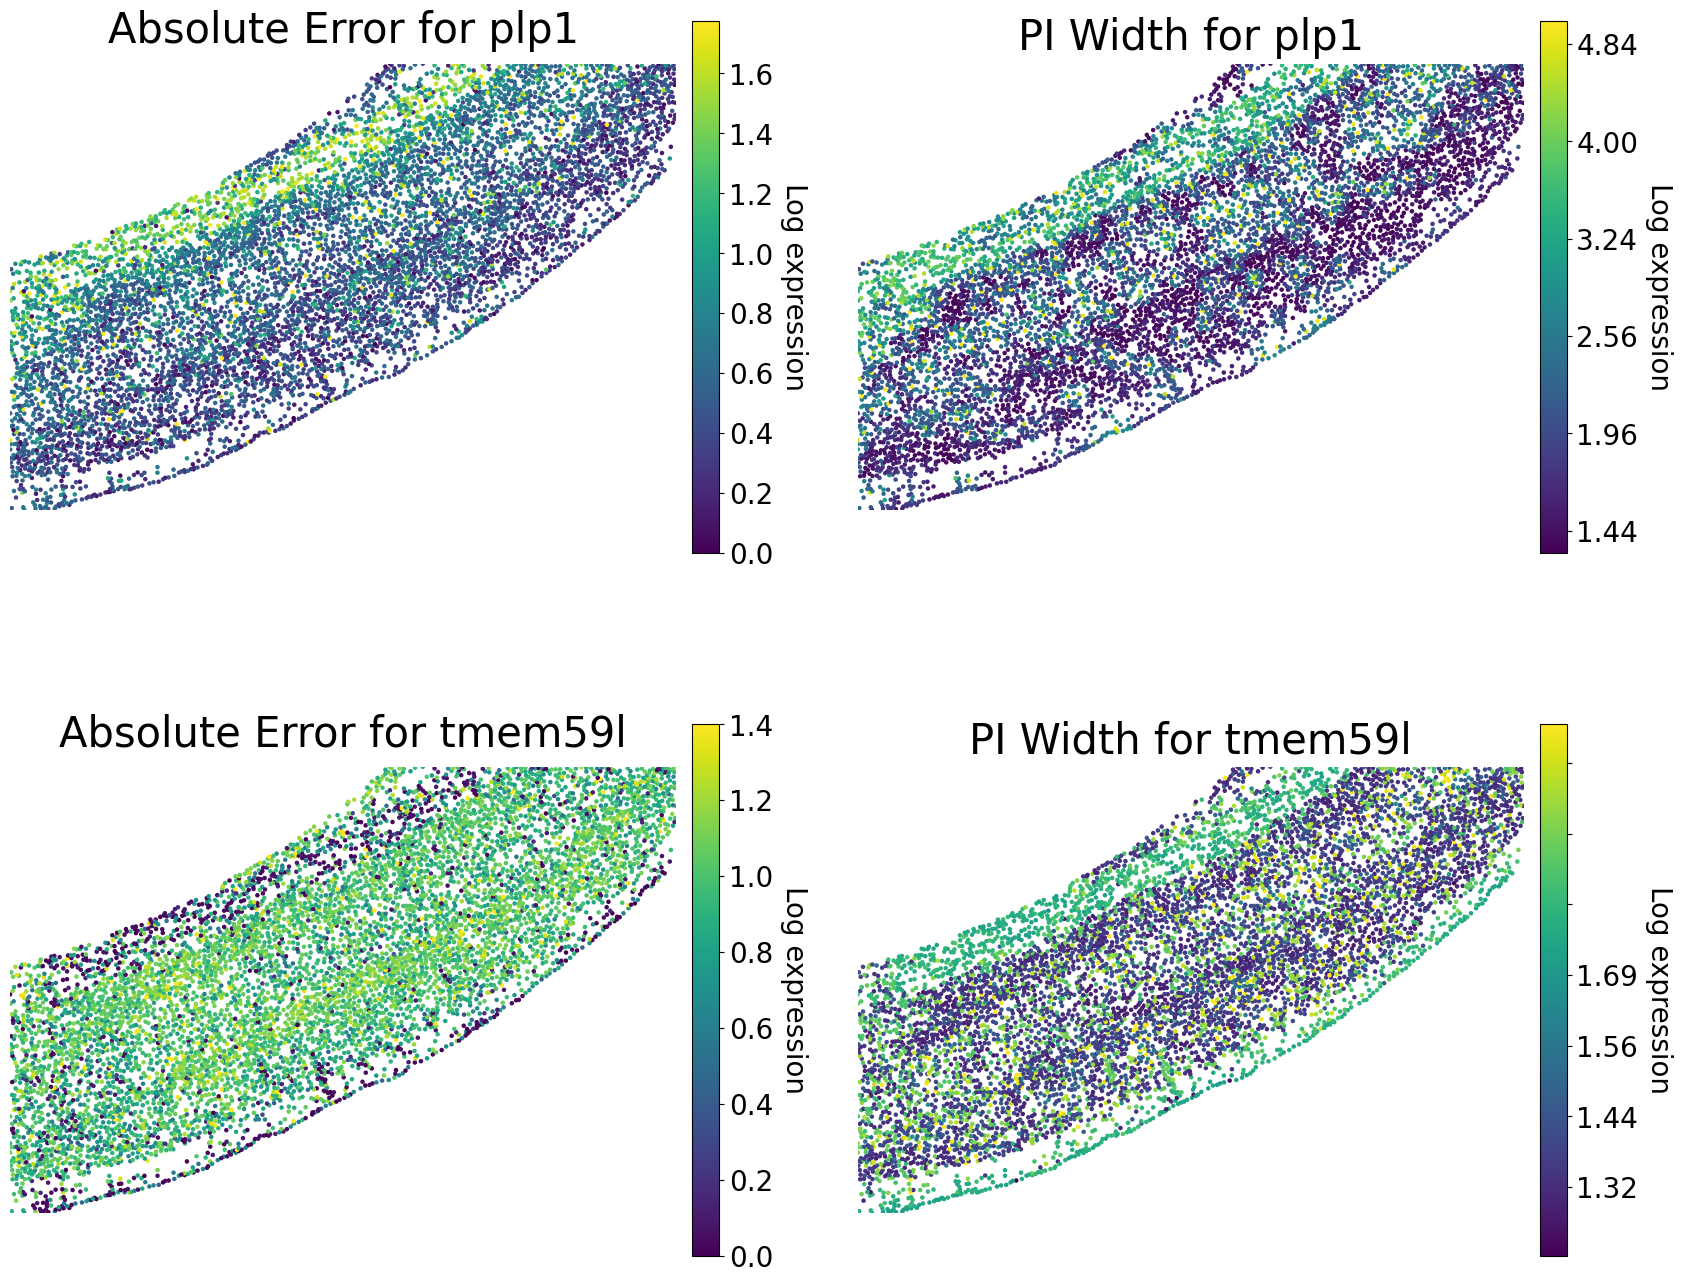

In [95]:
# --- helper ---------------------------------------------------------------
def add_cbar(fig, im, ax, power=None):
    """
    Attach a colour-bar with unified sizing.  If `power` is given, assume
    data were transformed with x**power and re-label ticks on the original
    scale.
    """
    cb = fig.colorbar(im, ax=ax, shrink=0.65, pad=0.02, aspect=20)
    cb.ax.tick_params(labelsize=20)
    if power is not None and power != 1:
        ticks = cb.get_ticks()
        cb.set_ticklabels([f"{t**(1/power):.2f}" for t in ticks])
    cb.set_label("Log expression", fontsize=20, rotation=270, labelpad=25)
    return cb

# --- 3. Zoomed visualisation ---------------------------------------------
n_genes = len(genes_to_plot)
fig, axes = plt.subplots(n_genes, 2, figsize=(18, 8 * n_genes), squeeze=False)
# fig.suptitle("Zoomed case studies: reliability of prediction intervals (SpaGE, D2)",
#              fontsize=22, weight='bold')

coords = adata_2.obsm['spatial']
xlim, ylim = (6000, 8500), (325, 2000)

for i, (_, gene_info) in enumerate(genes_to_plot.iterrows()):
    gene_name = gene_info['gene']

    err  = np.abs(adata_2.obsm['spage_predictions_error'][gene_name].values)
    pi_w = (adata_2.obsm['spage_predictions_hi'][gene_name].values -
            adata_2.obsm['spage_predictions_lo'][gene_name].values).clip(min=0)

    mask = ((coords[:, 0] >= xlim[0]) & (coords[:, 0] <= xlim[1]) &
            (coords[:, 1] >= ylim[0]) & (coords[:, 1] <= ylim[1]))
    cz, ez, pw = coords[mask], err[mask], pi_w[mask]

    # ---------------- absolute error -----------------
    err_vmin, err_vmax = np.min(ez), np.percentile(ez, 99)
    im_err = axes[i, 0].scatter(cz[:, 0], cz[:, 1], c=ez,
                                cmap='viridis', s=5,
                                vmin=err_vmin, vmax=err_vmax,
                                rasterized=True)
    add_cbar(fig, im_err, axes[i, 0])                     # same settings
    axes[i, 0].set_title(f"Absolute Error for {gene_name}",
                         fontsize=30, pad=15)

    # ---------------- PI width (sqrt) -----------------
    power = 0.5
    pw_t  = np.power(pw, power)
    pw_min, pw_max = np.min(pw_t), np.percentile(pw_t, 99)

    im_pi = axes[i, 1].scatter(cz[:, 0], cz[:, 1], c=pw_t,
                               cmap='viridis', s=5,
                               vmin=pw_min, vmax=pw_max,
                               rasterized=True)
    add_cbar(fig, im_pi, axes[i, 1], power=power)
    axes[i, 1].set_title(f"PI Width for {gene_name}",
                         fontsize=30, pad=10)

# --- axes cosmetics --------------------------------------------------------
for ax in axes.flatten():
    ax.set_aspect('equal', adjustable='box')
    ax.set_xticks([]); ax.set_yticks([])
    ax.set_xlim(xlim); ax.set_ylim(ylim)

sns.despine(left=True, bottom=True)
plt.tight_layout(rect=[0.05, 0, 1, 0.97])
plt.show()


--- Calculating correlation between error and PI width for 464 genes ---


Processing genes: 100%|██████████| 464/464 [00:01<00:00, 282.20it/s]



--- Summary of Correlation: True Error vs. PI Width ---
Number of genes successfully analyzed: 464
Mean Pearson Correlation: 0.069
Median Pearson Correlation: 0.008
Standard Deviation of Correlations: 0.234
Percentage of genes with positive correlation: 51.94%


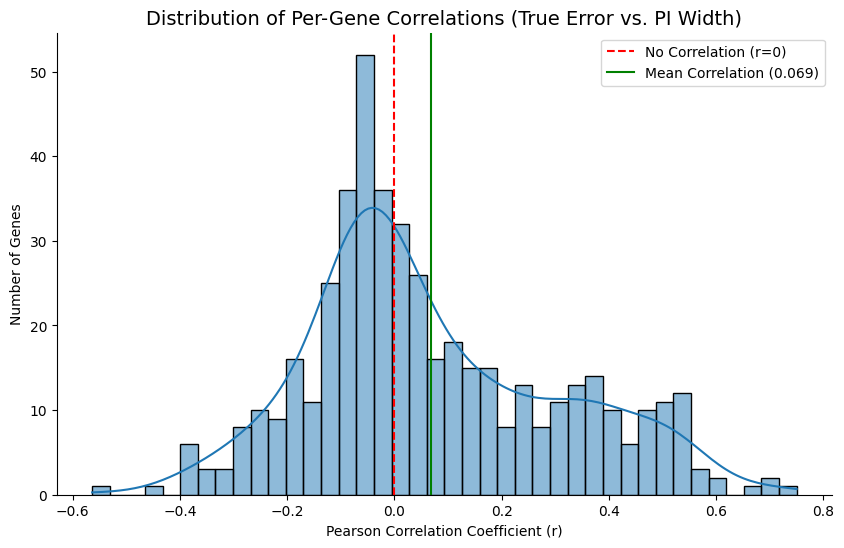

In [44]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
from scipy import stats
from tqdm import tqdm

# --- Analysis: Validate Prediction Interval Width as an Error Proxy ---
# Assumes 'adata' contains the outputs from the TISSUE pipeline.

# 1. Define the model key and get the list of genes
model_key = "spage_predictions" # The base key used in the TISSUE functions
genes_to_test = dataset.var_names

# 2. Extract necessary data matrices from adata
try:
    actual_matrix = dataset.X.toarray() if hasattr(dataset.X, 'toarray') else np.array(dataset.X)
    pred_matrix = dataset.obsm[model_key]
    pi_high_matrix = dataset.obsm[model_key + "_hi"]
    pi_low_matrix = dataset.obsm[model_key + "_lo"]
    
    # Ensure all components are pandas DataFrames for consistent indexing
    if not isinstance(pred_matrix, pd.DataFrame):
        pred_matrix = pd.DataFrame(pred_matrix, index=dataset.obs_names, columns=dataset.var_names)
    if not isinstance(pi_high_matrix, pd.DataFrame):
        pi_high_matrix = pd.DataFrame(pi_high_matrix, index=dataset.obs_names, columns=dataset.var_names)
    if not isinstance(pi_low_matrix, pd.DataFrame):
        pi_low_matrix = pd.DataFrame(pi_low_matrix, index=dataset.obs_names, columns=dataset.var_names)

    pi_width_matrix = pi_high_matrix - pi_low_matrix
    error_matrix = np.abs(actual_matrix - pred_matrix.values)
    
    # Convert error matrix to DataFrame for easier indexing
    error_df = pd.DataFrame(error_matrix, index=dataset.obs_names, columns=dataset.var_names)

    # 3. Calculate per-gene correlation between error and PI width
    correlations = []
    print(f"--- Calculating correlation between error and PI width for {len(genes_to_test)} genes ---")

    for gene in tqdm(genes_to_test, desc="Processing genes"):
        error_vec = error_df[gene].values
        pi_width_vec = pi_width_matrix[gene].values
        
        # Check for non-constant vectors to avoid correlation errors
        if np.std(error_vec) > 0 and np.std(pi_width_vec) > 0:
            corr, _ = stats.pearsonr(error_vec, pi_width_vec)
            if not np.isnan(corr):
                correlations.append(corr)

    correlations = np.array(correlations)

    # 4. Generate Textual Summary
    print("\n--- Summary of Correlation: True Error vs. PI Width ---")
    if len(correlations) > 0:
        print(f"Number of genes successfully analyzed: {len(correlations)}")
        print(f"Mean Pearson Correlation: {np.mean(correlations):.3f}")
        print(f"Median Pearson Correlation: {np.median(correlations):.3f}")
        print(f"Standard Deviation of Correlations: {np.std(correlations):.3f}")
        print(f"Percentage of genes with positive correlation: {np.mean(correlations > 0) * 100:.2f}%")
    else:
        print("No valid correlations could be calculated.")

    # 5. Visualize the distribution of correlations
    plt.figure(figsize=(10, 6))
    if len(correlations) > 0:
        sns.histplot(x=correlations, bins=40, kde=True)
        plt.axvline(x=0, color='red', linestyle='--', label='No Correlation (r=0)')
        plt.axvline(x=np.mean(correlations), color='green', linestyle='-', label=f'Mean Correlation ({np.mean(correlations):.3f})')
        
        plt.title('Distribution of Per-Gene Correlations (True Error vs. PI Width)', fontsize=14)
        plt.xlabel('Pearson Correlation Coefficient (r)')
        plt.ylabel('Number of Genes')
        plt.legend()
    else:
        plt.text(0.5, 0.5, "No data to display.", ha='center', va='center')
        plt.title('Distribution of Per-Gene Correlations')

    sns.despine()
    plt.show()

except KeyError as e:
    print(f"Execution failed. A required key was not found in adata: {e}")
    print("Please ensure you have run the TISSUE pipeline steps correctly.")
except Exception as e:
    print(f"An unexpected error occurred: {e}")

#END

In [46]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
from scipy import stats
from tqdm import tqdm

# --- Self-Contained Analysis: Relating Calibration Quality to Gene Properties ---
# Assumes 'adata' and 'tangram_gene_metrics_df' are available.

try:
    # --- Part 1: Re-calculate the Calibration Quality Score ---
    print("--- Part 1: Calculating calibration quality scores ---")
    model_key = "spage_predictions"
    genes_to_test = dataset.var_names

    # Extract necessary data matrices
    actual_matrix = dataset.X.toarray() if hasattr(dataset.X, 'toarray') else np.array(dataset.X)
    pred_matrix = pd.DataFrame(dataset.obsm[model_key], index=dataset.obs_names, columns=dataset.var_names)
    pi_high_matrix = pd.DataFrame(dataset.obsm[model_key + "_hi"], index=dataset.obs_names, columns=dataset.var_names)
    pi_low_matrix = pd.DataFrame(dataset.obsm[model_key + "_lo"], index=dataset.obs_names, columns=dataset.var_names)

    pi_width_matrix = pi_high_matrix - pi_low_matrix
    error_df = pd.DataFrame(np.abs(actual_matrix - pred_matrix.values), index=dataset.obs_names, columns=dataset.var_names)

    # Calculate per-gene correlation
    kmeans_correlations = []
    for gene in tqdm(genes_to_test, desc="Calculating scores"):
        error_vec = error_df[gene].values
        pi_width_vec = pi_width_matrix[gene].values
        if np.std(error_vec) > 0 and np.std(pi_width_vec) > 0:
            corr, _ = stats.pearsonr(error_vec, pi_width_vec)
            if not np.isnan(corr):
                kmeans_correlations.append(corr)
    
    print("Calibration quality scores calculated successfully.")

    # --- Part 2: Relate scores to gene properties ---
    print("\n--- Part 2: Correlating quality scores with gene properties ---")
    
    # Prepare the data for merging
    calibration_quality_df = pd.DataFrame({
        'gene': genes_to_test,
        'calibration_quality': kmeans_correlations
    }).set_index('gene')

    analysis_df = tangram_gene_metrics_d1.merge(calibration_quality_df, left_index=True, right_index=True)
    analysis_df_clean = analysis_df[['calibration_quality', 'moran_i', 'spearman_r']].dropna()

    # Generate Textual Summary
    corr_moran, _ = stats.spearmanr(analysis_df_clean['calibration_quality'], analysis_df_clean['moran_I'])
    corr_spearman, _ = stats.spearmanr(analysis_df_clean['calibration_quality'], analysis_df_clean['spearman_r'])
    
    print(f"Spearman Correlation (Calibration Quality vs. Moran's I):       {corr_moran:.3f}")
    print(f"Spearman Correlation (Calibration Quality vs. Imputation Spearman's r): {corr_spearman:.3f}")

    # Create Visualizations
    fig, axes = plt.subplots(1, 2, figsize=(16, 7))
    fig.suptitle('Investigating Drivers of TISSUE Calibration Quality', fontsize=16)

    # Plot 1: vs. Moran's I
    sns.regplot(data=analysis_df_clean, x='moran_I', y='calibration_quality', ax=axes[0], scatter_kws={'alpha': 0.4}, line_kws={'color': 'red'})
    axes[0].set_title("vs. Gene Spatial Autocorrelation")
    axes[0].set_xlabel("Moran's I (Actual Expression)")
    axes[0].set_ylabel("Calibration Quality (Error-PI Width Correlation)")
    axes[0].axhline(0, color='grey', linestyle='--')

    # Plot 2: vs. Spearman's r
    sns.regplot(data=analysis_df_clean, x='spearman_r', y='calibration_quality', ax=axes[1], scatter_kws={'alpha': 0.4}, line_kws={'color': 'red'})
    axes[1].set_title("vs. Gene Imputation Performance")
    axes[1].set_xlabel("Imputation Performance (Spearman's r)")
    axes[1].set_ylabel("")
    axes[1].axhline(0, color='grey', linestyle='--')

    sns.despine()
    plt.tight_layout(rect=[0, 0, 1, 0.95])
    plt.show()

except NameError as e:
    print(f"Execution failed. A required variable is not defined: {e}. Please ensure 'adata' and 'tangram_gene_metrics_df' are loaded.")
except KeyError as e:
    print(f"Execution failed. A required key was not found in adata: {e}. Please ensure the TISSUE pipeline has been run.")
except Exception as e:
    print(f"An unexpected error occurred: {e}")

#END

--- Part 1: Calculating calibration quality scores ---


Calculating scores: 100%|██████████| 464/464 [00:01<00:00, 310.09it/s]

Calibration quality scores calculated successfully.

--- Part 2: Correlating quality scores with gene properties ---
Execution failed. A required key was not found in adata: "['moran_i'] not in index". Please ensure the TISSUE pipeline has been run.


**Our comprehensive evaluation of Tangram and SpaGE reveals that while both models can effectively impute spatially coherent genes, their overall performance on this dataset is statistically indistinguishable. We demonstrated that the primary determinant of imputation success for both methods is the intrinsic spatial structure of a gene; genes with high spatial autocorrelation (Moran's I) are reconstructed with high fidelity, while performance degrades significantly for sparser, less structured genes. A rigorous bootstrap analysis of a holistic Area Under the Curve (AUC) metric confirmed that the minor observed performance differences between the models lack statistical significance.
Recognizing that the ultimate utility of such models lies in predicting novel or unmeasured genes, we subsequently assessed the reliability of uncertainty estimates from the state-of-the-art TISSUE framework. This analysis exposed a critical limitation: the model's calibration failed on this dataset. The correlation between the true imputation error and the estimated Prediction Interval (PI) width—the key proxy for uncertainty—was, on average, near zero (mean Pearson's r ≈ 0.07). This indicates that the reported uncertainty is not a reliable indicator of prediction accuracy. Crucially, this failure was comprehensive; even for well-imputed genes with strong spatial patterns, the PI width provided no meaningful information about the magnitude of the error. We therefore conclude that for this dataset, while imputation can reconstruct known patterns, the uncertainty quantification is not dependable, precluding confident biological interpretation of predictions for unmeasured genes and highlighting the profound challenge that data sparsity poses even to advanced calibration methods.**